# Impact of 6G Network Performance on Manufacturing Efficiency in Smart Factories

## Project Overview

### Objective

Analyze how 6G network performance, particularly network latency and packet loss, is associated with manufacturing efficiency, production speed, operational errors, and quality defects in smart factory environments.

### Business Problem

Manufacturing performance issues may not always be attributable to machine or process conditions alone. Network degradation, such as increased communication latency or packet loss, may be associated with reduced production efficiency, increased operational errors, and higher defect rates.

This analysis investigates these relationships to identify network-performance conditions associated with manufacturing performance changes.

### Analytical Questions

1. What does observed network performance look like in the dataset?
2. How does efficiency vary across different network-quality levels?
3. How does production performance vary across latency ranges, and are there ranges associated with noticeable changes?
4. How does packet loss relate to operational error rate?
5. How does packet loss relate to quality-control defect rate?
6. Which operation modes appear more sensitive to network degradation?
7. What network conditions are associated with High, Medium, and Low efficiency?
8. What network-performance ranges or risk zones, if any, can be identified from the data?

### Project Scope

This project focuses on descriptive, diagnostic, and business-oriented manufacturing analytics. The analysis will investigate associations between network performance and manufacturing outcomes using the provided dataset.

No predictive machine-learning model will be introduced unless the actual project requirements and dataset analysis establish a clear need for one.

## Imports & Configuration

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

## Data Loading

### Loading the Raw Dataset

The raw manufacturing dataset is loaded from the project data directory into `df_raw`. A working copy, `df`, is created for subsequent auditing and analysis so that the original loaded data remains unchanged during the initial audit stage.

In [2]:
data_path = Path("../Data/raw/Thales_Group_Manufacturing.csv")

df_raw = pd.read_csv(data_path)

df = df_raw.copy()

## Initial Dataset Audit

### Audit Objective

This section establishes the structure, completeness, consistency, and initial validity of the raw dataset before any cleaning or transformation is performed.

The audit includes:
- Dataset dimensions and column inventory
- Data types and missing values
- Duplicate records and repeated timestamps
- Categorical and machine-level coverage
- Date and timestamp consistency
- Numeric ranges and suspicious values
- Structural anomalies requiring investigation

No records are removed or modified during this audit.

In [3]:
df.shape

(100000, 14)

In [4]:
df.columns

Index(['Date', 'Timestamp', 'Machine_ID', 'Operation_Mode', 'Temperature_C',
       'Vibration_Hz', 'Power_Consumption_kW', 'Network_Latency_ms',
       'Packet_Loss_%', 'Quality_Control_Defect_Rate_%',
       'Production_Speed_units_per_hr', 'Predictive_Maintenance_Score',
       'Error_Rate_%', 'Efficiency_Status'],
      dtype='object')

In [5]:
df.dtypes

Date                              object
Timestamp                         object
Machine_ID                         int64
Operation_Mode                    object
Temperature_C                    float64
Vibration_Hz                     float64
Power_Consumption_kW             float64
Network_Latency_ms               float64
Packet_Loss_%                    float64
Quality_Control_Defect_Rate_%    float64
Production_Speed_units_per_hr    float64
Predictive_Maintenance_Score     float64
Error_Rate_%                     float64
Efficiency_Status                 object
dtype: object

In [6]:
missing_summary = pd.DataFrame({
    'Missing_Count': df.isnull().sum(),
    'Missing_Percentage': (df.isnull().mean() * 100).round(2)
})

missing_summary

,Missing_Count,Missing_Percentage
Date,0,0.0
Timestamp,0,0.0
Machine_ID,0,0.0
Operation_Mode,0,0.0
Temperature_C,0,0.0
Vibration_Hz,0,0.0
Power_Consumption_kW,0,0.0
Network_Latency_ms,0,0.0
Packet_Loss_%,0,0.0
Quality_Control_Defect_Rate_%,0,0.0


In [7]:
df.duplicated().sum()

np.int64(0)

In [8]:
df['Operation_Mode'].unique()

array(['Idle', 'Active', 'Maintenance'], dtype=object)

In [9]:
df['Efficiency_Status'].unique()

array(['Low', 'Medium', 'High'], dtype=object)

In [10]:
df['Machine_ID'].nunique()

50

In [11]:
df[['Date', 'Timestamp']].head()

,Date,Timestamp
0,01-01-2025,00:00:00
1,01-01-2025,00:01:00
2,01-01-2025,00:02:00
3,01-01-2025,00:03:00
4,01-01-2025,00:04:00


In [12]:
df[['Date', 'Timestamp']].tail()

,Date,Timestamp
99995,10-03-2025,10:35:00
99996,10-03-2025,10:36:00
99997,10-03-2025,10:37:00
99998,10-03-2025,10:38:00
99999,10-03-2025,10:39:00


In [13]:
df['Timestamp'].nunique()

1440

In [14]:
df['Date'].nunique()

69

In [15]:
dates = pd.to_datetime(
    df['Date'],
    format='%d-%m-%Y'
).dt.date

date_gaps = (
    pd.Series(dates)
    .drop_duplicates()
    .sort_values()
    .diff()
)

date_gaps.value_counts()

Date
1 days    68
Name: count, dtype: int64

In [16]:
df.groupby('Date')['Timestamp'].nunique().describe()

count      69.000000
mean     1428.405797
std        96.308682
min       640.000000
25%      1440.000000
50%      1440.000000
75%      1440.000000
max      1440.000000
Name: Timestamp, dtype: float64

In [17]:
df.duplicated(subset=['Date', 'Timestamp']).sum()

np.int64(1440)

In [18]:
df.groupby(['Date', 'Timestamp']).size().value_counts()

1    97120
2     1440
Name: count, dtype: int64

In [19]:
df.loc[
    df.duplicated(subset=['Date', 'Timestamp'], keep=False),
    ['Date', 'Timestamp', 'Machine_ID']
].head(20)

,Date,Timestamp,Machine_ID
84960,01-03-2025,00:00:00,49
84961,01-03-2025,00:01:00,35
84962,01-03-2025,00:02:00,22
84963,01-03-2025,00:03:00,21
84964,01-03-2025,00:04:00,28
84965,01-03-2025,00:05:00,17
84966,01-03-2025,00:06:00,50
84967,01-03-2025,00:07:00,18
84968,01-03-2025,00:08:00,32
84969,01-03-2025,00:09:00,23


In [20]:
df.duplicated(subset=['Date', 'Timestamp', 'Machine_ID']).sum()

np.int64(28)

In [21]:
df_0301 = df[df['Date'] == '01-03-2025'].copy()

df_0301[['Timestamp', 'Machine_ID']].iloc[:1440].reset_index(drop=True).equals(
    df_0301[['Timestamp', 'Machine_ID']].iloc[1440:].reset_index(drop=True)
)

False

In [22]:
df_0301.groupby('Timestamp')['Machine_ID'].nunique().value_counts().sort_index()

Machine_ID
1      28
2    1412
Name: count, dtype: int64

In [23]:
df_0301['Machine_ID'].nunique()

50

In [24]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
Machine_ID,100000.0,25.499330,14.389439,1.0,13.00000,25.0000,38.00000,50.000
Temperature_C,100000.0,60.041460,17.323239,30.0,45.03150,60.0335,74.96725,89.999
Vibration_Hz,100000.0,2.549959,1.414127,0.1,1.32300,2.5490,3.77600,5.000
Power_Consumption_kW,100000.0,5.745929,2.451271,1.5,3.62700,5.7550,7.86000,10.000
Network_Latency_ms,100000.0,25.555620,14.120760,1.0,13.35500,25.5360,37.79625,50.000
Packet_Loss_%,100000.0,2.493418,1.443273,0.0,1.24500,2.4880,3.74100,5.000
Quality_Control_Defect_Rate_%,100000.0,5.008806,2.883666,0.0,2.52175,5.0035,7.50600,10.000
Production_Speed_units_per_hr,100000.0,275.916324,130.096892,50.0,162.87375,276.6490,388.81250,499.997
Predictive_Maintenance_Score,100000.0,0.499384,0.288814,0.0,0.24800,0.4990,0.74900,1.000
Error_Rate_%,100000.0,7.504101,4.335895,0.0,3.75000,7.5040,11.27300,15.000


In [25]:
range_checks = {
    'Packet_Loss_%': (
        (df['Packet_Loss_%'] < 0) |
        (df['Packet_Loss_%'] > 100)
    ).sum(),

    'Quality_Control_Defect_Rate_%': (
        (df['Quality_Control_Defect_Rate_%'] < 0) |
        (df['Quality_Control_Defect_Rate_%'] > 100)
    ).sum(),

    'Error_Rate_%': (
        (df['Error_Rate_%'] < 0) |
        (df['Error_Rate_%'] > 100)
    ).sum(),

    'Predictive_Maintenance_Score': (
       (df['Predictive_Maintenance_Score'] < 0) |
       (df['Predictive_Maintenance_Score'] > 1)
    ).sum()
}

pd.Series(range_checks, name='Invalid_Value_Count')

Packet_Loss_%                    0
Quality_Control_Defect_Rate_%    0
Error_Rate_%                     0
Predictive_Maintenance_Score     0
Name: Invalid_Value_Count, dtype: int64

In [26]:
df_0301['Timestamp'].iloc[:1440].reset_index(drop=True).equals(
    df_0301['Timestamp'].iloc[1440:].reset_index(drop=True)
)

True

In [27]:
first_block_machines = set(df_0301['Machine_ID'].iloc[:1440])
second_block_machines = set(df_0301['Machine_ID'].iloc[1440:])

len(first_block_machines), len(second_block_machines), len(first_block_machines & second_block_machines)

(50, 50, 50)

In [28]:
block_1 = df_0301.iloc[:1440]
block_2 = df_0301.iloc[1440:]

block_comparison = pd.DataFrame({
    'Block_1_Mean': block_1.select_dtypes(include='number').mean(),
    'Block_2_Mean': block_2.select_dtypes(include='number').mean(),
    'Block_1_Std': block_1.select_dtypes(include='number').std(),
    'Block_2_Std': block_2.select_dtypes(include='number').std()
}).round(3)

block_comparison

,Block_1_Mean,Block_2_Mean,Block_1_Std,Block_2_Std
Machine_ID,25.857,25.824,14.335,14.280
Temperature_C,60.047,58.440,17.409,17.168
Vibration_Hz,2.534,2.566,1.421,1.418
Power_Consumption_kW,5.818,5.808,2.416,2.396
Network_Latency_ms,25.970,25.165,14.227,14.286
Packet_Loss_%,2.531,2.539,1.432,1.429
Quality_Control_Defect_Rate_%,5.031,4.956,2.829,2.877
Production_Speed_units_per_hr,279.512,279.203,131.665,130.167
Predictive_Maintenance_Score,0.487,0.501,0.290,0.291
Error_Rate_%,7.582,7.435,4.298,4.308


In [29]:
df_0301.iloc[1440:][['Date', 'Timestamp']].reset_index(drop=True).equals(
    df_0301.iloc[:1440][['Date', 'Timestamp']].reset_index(drop=True)
)

True

In [30]:
audit_summary = pd.DataFrame({
    'Data_Type': df.dtypes,
    'Unique_Values': df.nunique(),
    'Missing_Count': df.isnull().sum(),
    'Missing_Percentage': (df.isnull().mean() * 100).round(2)
})

audit_summary

,Data_Type,Unique_Values,Missing_Count,Missing_Percentage
Date,object,69,0,0.0
Timestamp,object,1440,0,0.0
Machine_ID,int64,50,0,0.0
Operation_Mode,object,3,0,0.0
Temperature_C,float64,48598,0,0.0
Vibration_Hz,float64,4901,0,0.0
Power_Consumption_kW,float64,8501,0,0.0
Network_Latency_ms,float64,42645,0,0.0
Packet_Loss_%,float64,5001,0,0.0
Quality_Control_Defect_Rate_%,float64,10001,0,0.0


### Audit Summary

The initial audit has established the dataset structure, temporal coverage, completeness, duplicate patterns, numeric ranges, and identified structural anomalies requiring further investigation.

The raw dataset remains unchanged. The next section applies data-quality checks and defines the cleaning policy based on the findings from this audit.

## Data Quality & Cleaning

### Cleaning Objective

This section prepares the audited dataset for analysis by applying only justified data-quality corrections and preserving valid observations.

The cleaning process focuses on:
- Standardizing date and timestamp fields for analysis
- Checking and validating missing or invalid values
- Checking duplicate records without removing structurally valid observations
- Preserving the identified timestamp anomaly on 01-03-2025 because the additional records are not identical duplicates
- Creating the cleaned analysis dataset used in subsequent sections

Cleaning decisions are based on the audit findings and are documented before the analytical metrics and network-performance analyses are performed.

In [31]:
df_clean = df.copy()

In [32]:
df_clean['Structural_Anomaly'] = df_clean['Date'].eq('01-03-2025')

In [33]:
numeric_measure_cols = [
    'Temperature_C',
    'Vibration_Hz',
    'Power_Consumption_kW',
    'Network_Latency_ms',
    'Packet_Loss_%',
    'Quality_Control_Defect_Rate_%',
    'Production_Speed_units_per_hr',
    'Predictive_Maintenance_Score',
    'Error_Rate_%'
]

df_clean[numeric_measure_cols].lt(0).sum()

Temperature_C                    0
Vibration_Hz                     0
Power_Consumption_kW             0
Network_Latency_ms               0
Packet_Loss_%                    0
Quality_Control_Defect_Rate_%    0
Production_Speed_units_per_hr    0
Predictive_Maintenance_Score     0
Error_Rate_%                     0
dtype: int64

In [34]:
categorical_cols = ['Operation_Mode', 'Efficiency_Status']

for col in categorical_cols:
    print(f"\n{col}:")
    print(df_clean[col].value_counts(dropna=False))


Operation_Mode:
Operation_Mode
Active         70054
Idle           20057
Maintenance     9889
Name: count, dtype: int64

Efficiency_Status:
Efficiency_Status
Low       77825
Medium    19189
High       2986
Name: count, dtype: int64


In [35]:
df_clean[
    ['Packet_Loss_%',
     'Quality_Control_Defect_Rate_%',
     'Predictive_Maintenance_Score',
     'Error_Rate_%']
].agg(['min', 'max'])

,Packet_Loss_%,Quality_Control_Defect_Rate_%,Predictive_Maintenance_Score,Error_Rate_%
min,0.0,0.0,0.0,0.0
max,5.0,10.0,1.0,15.0


In [36]:
df_clean[
    ['Temperature_C',
     'Vibration_Hz',
     'Power_Consumption_kW',
     'Network_Latency_ms',
     'Production_Speed_units_per_hr']
].agg(['min', 'max'])

,Temperature_C,Vibration_Hz,Power_Consumption_kW,Network_Latency_ms,Production_Speed_units_per_hr
min,30.000,0.1,1.5,1.0,50.000
max,89.999,5.0,10.0,50.0,499.997


In [37]:
range_checks = {
    'Packet_Loss_%': (
        (df_clean['Packet_Loss_%'] < 0) |
        (df_clean['Packet_Loss_%'] > 100)
    ).sum(),

    'Quality_Control_Defect_Rate_%': (
        (df_clean['Quality_Control_Defect_Rate_%'] < 0) |
        (df_clean['Quality_Control_Defect_Rate_%'] > 100)
    ).sum(),

    'Error_Rate_%': (
        (df_clean['Error_Rate_%'] < 0) |
        (df_clean['Error_Rate_%'] > 100)
    ).sum(),

    'Predictive_Maintenance_Score': (
    (df_clean['Predictive_Maintenance_Score'] < 0) |
    (df_clean['Predictive_Maintenance_Score'] > 1)
    ).sum() 
}

pd.Series(range_checks, name='Invalid_Value_Count')

Packet_Loss_%                    0
Quality_Control_Defect_Rate_%    0
Error_Rate_%                     0
Predictive_Maintenance_Score     0
Name: Invalid_Value_Count, dtype: int64

In [38]:
df_clean['Date'] = pd.to_datetime(
    df_clean['Date'],
    format='%d-%m-%Y'
)

df_clean['Timestamp'] = pd.to_timedelta(
    df_clean['Timestamp']
)

df_clean[['Date', 'Timestamp']].dtypes

Date          datetime64[ns]
Timestamp    timedelta64[ns]
dtype: object

In [39]:
df_clean['Datetime'] = df_clean['Date'] + df_clean['Timestamp']

df_clean[['Date', 'Timestamp', 'Datetime']].head()

,Date,Timestamp,Datetime
0,2025-01-01,0 days 00:00:00,2025-01-01 00:00:00
1,2025-01-01,0 days 00:01:00,2025-01-01 00:01:00
2,2025-01-01,0 days 00:02:00,2025-01-01 00:02:00
3,2025-01-01,0 days 00:03:00,2025-01-01 00:03:00
4,2025-01-01,0 days 00:04:00,2025-01-01 00:04:00


In [40]:
df_clean['Datetime'].agg(['min', 'max', 'count'])

min      2025-01-01 00:00:00
max      2025-03-10 10:39:00
count                 100000
Name: Datetime, dtype: object

In [41]:
print(
    "Datetime globally monotonic:",
    df_clean['Datetime'].is_monotonic_increasing
)

Datetime globally monotonic: False


In [42]:
(df_clean['Datetime'].diff() < pd.Timedelta(0)).sum()

np.int64(1)

In [43]:
df_clean.loc[
    df_clean['Datetime'].diff() < pd.Timedelta(0),
    ['Date', 'Timestamp', 'Datetime', 'Machine_ID']
]

,Date,Timestamp,Datetime,Machine_ID
86400,2025-03-01,0 days,2025-03-01,5


### Data Quality Finding: 01-03-2025 Structural Anomaly

The dataset contains 2,880 observations for 01-03-2025, compared with 1,440 observations on other complete dates. The timestamp sequence for this date consists of two consecutive copies of the same 1,440-minute sequence, producing one backward chronological transition at the start of the second block.

The two blocks are not identical at the row level, and their machine ordering and measurements differ. Therefore, the duplicated block cannot be safely removed based on the available evidence.

The observations are retained in `df_clean`, while `Structural_Anomaly` flags all rows belonging to 01-03-2025 for transparent documentation and interpretation of the dataset structure.

No records are removed solely because of this structural anomaly.

In [44]:
df_clean.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 100000 entries, 0 to 99999
Data columns (total 16 columns):
 #   Column                         Non-Null Count   Dtype          
---  ------                         --------------   -----          
 0   Date                           100000 non-null  datetime64[ns] 
 1   Timestamp                      100000 non-null  timedelta64[ns]
 2   Machine_ID                     100000 non-null  int64          
 3   Operation_Mode                 100000 non-null  object         
 4   Temperature_C                  100000 non-null  float64        
 5   Vibration_Hz                   100000 non-null  float64        
 6   Power_Consumption_kW           100000 non-null  float64        
 7   Network_Latency_ms             100000 non-null  float64        
 8   Packet_Loss_%                  100000 non-null  float64        
 9   Quality_Control_Defect_Rate_%  100000 non-null  float64        
 10  Production_Speed_units_per_hr  100000 non-null  float64  

In [45]:
df_clean.describe().T

,count,mean,min,25%,50%,75%,max,std
Date,100000,2025-02-04 02:06:43.200000,2025-01-01 00:00:00,2025-01-18 00:00:00,2025-02-04 00:00:00,2025-02-22 00:00:00,2025-03-10 00:00:00,NaN
Timestamp,100000,0 days 11:56:56.400000,0 days 00:00:00,0 days 05:57:00,0 days 11:55:00,0 days 17:57:00,0 days 23:59:00,0 days 06:55:51.029088567
Machine_ID,100000.0,25.49933,1.0,13.0,25.0,38.0,50.0,14.389439
Temperature_C,100000.0,60.04146,30.0,45.0315,60.0335,74.96725,89.999,17.323239
Vibration_Hz,100000.0,2.549959,0.1,1.323,2.549,3.776,5.0,1.414127
Power_Consumption_kW,100000.0,5.745929,1.5,3.627,5.755,7.86,10.0,2.451271
Network_Latency_ms,100000.0,25.55562,1.0,13.355,25.536,37.79625,50.0,14.12076
Packet_Loss_%,100000.0,2.493418,0.0,1.245,2.488,3.741,5.0,1.443273
Quality_Control_Defect_Rate_%,100000.0,5.008806,0.0,2.52175,5.0035,7.506,10.0,2.883666
Production_Speed_units_per_hr,100000.0,275.916324,50.0,162.87375,276.649,388.8125,499.997,130.096892


## Analytical Metric Preparation

### Network Stability Index

The Network Stability Index (NSI) provides a combined, normalized measure of network stability using the two available network-performance indicators: latency and packet loss.

Latency and packet loss are normalized to a common 0–1 scale and combined using equal weights. Because both indicators represent network degradation when their values increase, the combined score is inverted so that a higher NSI represents greater observed network stability.

Equal weighting was selected to give latency and packet loss equal influence because no external weighting scheme was specified in the project requirements.

The index is used as a dataset-relative analytical measure for comparing network conditions across observations and periods. It is not intended to represent a universal 6G engineering standard.

In [46]:
network_norm = df_clean[
    ['Network_Latency_ms', 'Packet_Loss_%']
].copy()

network_norm['Latency_Normalized'] = (
    (network_norm['Network_Latency_ms'] - network_norm['Network_Latency_ms'].min())
    / (
        network_norm['Network_Latency_ms'].max()
        - network_norm['Network_Latency_ms'].min()
    )
)

network_norm['Packet_Loss_Normalized'] = (
    (network_norm['Packet_Loss_%'] - network_norm['Packet_Loss_%'].min())
    / (
        network_norm['Packet_Loss_%'].max()
        - network_norm['Packet_Loss_%'].min()
    )
)

network_norm['Network_Stability_Index'] = (
    1 - (
        0.5 * network_norm['Latency_Normalized']
        + 0.5 * network_norm['Packet_Loss_Normalized']
    )
)

df_clean['Network_Stability_Index'] = (
    network_norm['Network_Stability_Index'].to_numpy()
)

In [47]:
df_clean['Network_Quality'] = pd.qcut(
    df_clean['Network_Stability_Index'],
    q=3,
    labels=['Low', 'Medium', 'High']
)

In [48]:
df_clean[
    [
        'Network_Latency_ms',
        'Packet_Loss_%',
        'Network_Stability_Index',
        'Network_Quality'
    ]
].describe(include='all')

,Network_Latency_ms,Packet_Loss_%,Network_Stability_Index,Network_Quality
count,100000.00000,100000.000000,100000.000000,100000
unique,NaN,NaN,NaN,3
top,NaN,NaN,NaN,Low
freq,NaN,NaN,NaN,33334
mean,25.55562,2.493418,0.500091,NaN
std,14.12076,1.443273,0.203238,NaN
min,1.00000,0.000000,0.001478,NaN
25%,13.35500,1.245000,0.355038,NaN
50%,25.53600,2.488000,0.500008,NaN
75%,37.79625,3.741000,0.645283,NaN


## Network Performance Profiling

### Analyze Latency and Packet Loss Distributions

This section establishes the observed behavior of network latency and packet loss before relating network conditions to manufacturing outcomes.

The analysis examines:

- Distribution, central tendency, variation, and observed ranges of latency and packet loss
- Temporal variation in network conditions across dates and clock times
- Relative network-quality segmentation based on the Network Stability Index

These observations describe the network conditions present in this dataset and are not interpreted as universal 6G engineering thresholds.

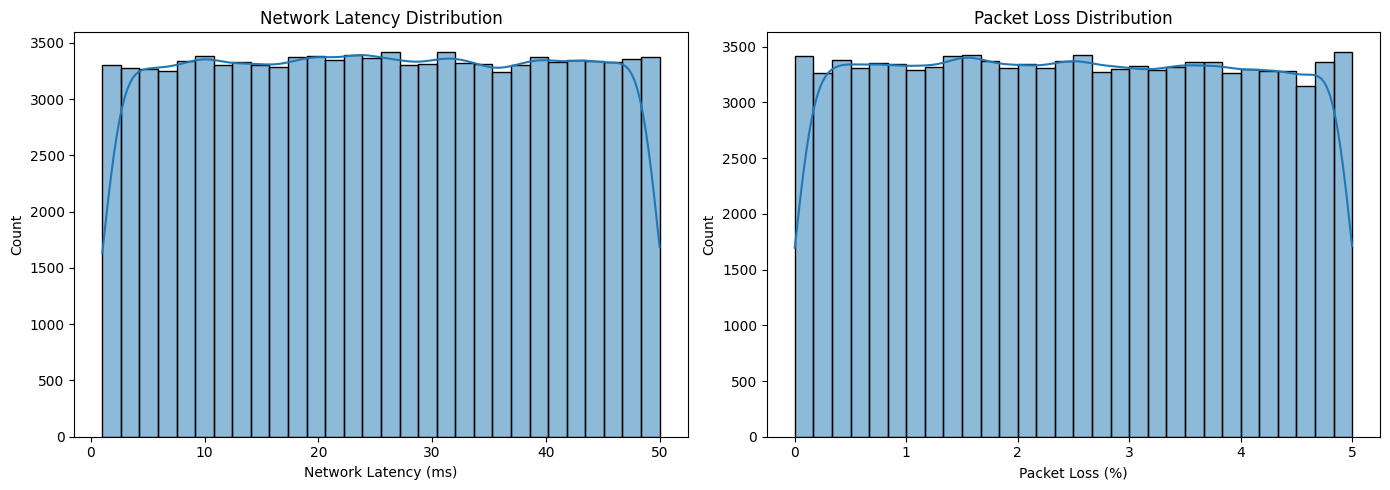

Saved: ..\Outputs\Figures\F01_Network_Performance_Distributions.png


In [100]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.histplot(
    df_clean['Network_Latency_ms'],
    bins=30,
    kde=True,
    ax=axes[0]
)
axes[0].set_title('Network Latency Distribution')
axes[0].set_xlabel('Network Latency (ms)')
axes[0].set_ylabel('Count')

sns.histplot(
    df_clean['Packet_Loss_%'],
    bins=30,
    kde=True,
    ax=axes[1]
)
axes[1].set_title('Packet Loss Distribution')
axes[1].set_xlabel('Packet Loss (%)')
axes[1].set_ylabel('Count')

plt.tight_layout()

output_dir = Path("../Outputs/Figures")
output_dir.mkdir(parents=True, exist_ok=True)

figure_path = output_dir / "F01_Network_Performance_Distributions.png"
fig.savefig(figure_path, dpi=300, bbox_inches="tight")

plt.show()

print(f"Saved: {figure_path}")

In [50]:
network_distribution_summary = (
    df_clean[
        ['Network_Latency_ms', 'Packet_Loss_%']
    ]
    .agg(['count', 'mean', 'median', 'std', 'min', 'max'])
    .T
    .round(3)
)

network_distribution_summary

,count,mean,median,std,min,max
Network_Latency_ms,100000.0,25.556,25.536,14.121,1.0,50.0
Packet_Loss_%,100000.0,2.493,2.488,1.443,0.0,5.0


In [51]:
network_percentiles = (
    df_clean[
        ['Network_Latency_ms', 'Packet_Loss_%']
    ]
    .quantile([0.05, 0.10, 0.25, 0.50, 0.75, 0.90, 0.95])
    .round(3)
)

network_percentiles

,Network_Latency_ms,Packet_Loss_%
0.05,3.501,0.249
0.10,5.983,0.497
0.25,13.355,1.245
0.50,25.536,2.488
0.75,37.796,3.741
0.90,45.125,4.498
0.95,47.584,4.755


### Distribution Interpretation

Network latency and packet loss show variation across individual observations, with median values of approximately 25.5 ms and 2.5%, respectively. The percentile ranges describe the observed spread of network conditions within the dataset and provide reference points for subsequent comparisons.

These values describe the observed network conditions in this dataset only. They are used as analytical reference points for subsequent comparisons and should not be interpreted as universal 6G engineering limits.

These distribution summaries establish the observed network-performance range used in the subsequent stability and network-quality analyses.

### Assess Network Stability Across Periods

To assess whether network conditions vary substantially across periods, latency and packet loss are examined at the date and timestamp levels.

Daily and timestamp-level summaries are used to evaluate whether network conditions show meaningful temporal variation. Within-day variability is also examined using the standard deviation and observed range of latency and packet loss.

Because the dataset contains irregular machine-level observation intervals, temporal patterns are interpreted descriptively rather than as continuous real-time network states.

In [52]:
df_clean.groupby('Date')[
    ['Network_Latency_ms', 'Packet_Loss_%']
].mean().describe()

,Network_Latency_ms,Packet_Loss_%
count,69.000000,69.000000
mean,25.556325,2.492742
std,0.337430,0.035931
min,24.694892,2.415627
25%,25.430649,2.473713
50%,25.575172,2.497409
75%,25.758224,2.510969
max,26.499602,2.604858


In [53]:
daily_network_variability = (
    df_clean
    .groupby('Date')[
        ['Network_Latency_ms', 'Packet_Loss_%']
    ]
    .agg(['std', 'min', 'max'])
)

daily_network_variability

Network_Latency_ms                Packet_Loss_%              
                          std    min     max           std    min    max
Date                                                                    
2025-01-01          14.449032  1.017  49.982      1.457293  0.007  5.000
2025-01-02          14.424678  1.006  49.958      1.453303  0.000  5.000
2025-01-03          14.040802  1.038  49.951      1.409375  0.002  4.999
2025-01-04          14.078940  1.027  49.888      1.437571  0.003  5.000
2025-01-05          14.271615  1.022  49.983      1.457165  0.003  4.999
...                       ...    ...     ...           ...    ...    ...
2025-03-06          14.054838  1.143  49.972      1.450961  0.005  4.992
2025-03-07          14.229790  1.005  49.998      1.417698  0.005  5.000
2025-03-08          14.130396  1.045  49.996      1.465561  0.003  4.999
2025-03-09          14.167813  1.044  49.954      1.429369  0.001  4.999
2025-03-10          14.095955  1.165  49.970      1.480564  0.004  4.985

[69 rows x 6 columns]

In [54]:
daily_network_variability.describe().round(3)

Network_Latency_ms                 Packet_Loss_%                
                     std     min     max           std     min     max
count             69.000  69.000  69.000        69.000  69.000  69.000
mean              14.118   1.040  49.964         1.444   0.004   4.997
std                0.163   0.046   0.034         0.017   0.003   0.004
min               13.742   1.000  49.835         1.409   0.000   4.981
25%               14.019   1.012  49.953         1.433   0.002   4.995
50%               14.139   1.022  49.974         1.443   0.003   4.998
75%               14.245   1.048  49.986         1.453   0.005   4.999
max               14.449   1.195  50.000         1.481   0.019   5.000

In [55]:
df_clean.groupby('Timestamp')[
    ['Network_Latency_ms', 'Packet_Loss_%']
].mean().describe()

,Network_Latency_ms,Packet_Loss_%
count,1440.000000,1440.000000
mean,25.555349,2.493430
std,1.711484,0.176007
min,20.255797,1.837681
25%,24.399514,2.374634
50%,25.641136,2.489036
75%,26.647406,2.607575
max,31.612870,3.048159


In [56]:
daily_network_profile = (
    df_clean.groupby('Date')['Network_Stability_Index']
    .agg(['mean', 'median', 'std', 'min', 'max'])
)

daily_network_profile.describe().round(3)

,mean,median,std,min,max
count,69.000,69.000,69.000,69.000,69.000
mean,0.500,0.500,0.203,0.017,0.983
std,0.005,0.007,0.003,0.007,0.009
min,0.481,0.482,0.196,0.001,0.961
25%,0.497,0.496,0.201,0.012,0.976
50%,0.500,0.500,0.203,0.016,0.984
75%,0.504,0.503,0.205,0.022,0.990
max,0.512,0.519,0.211,0.031,0.999


### Note on Visualization Scale

The y-axis is intentionally limited to 0.45–0.55 to make the small day-to-day variation visible; the Network Stability Index itself is normalized over the broader 0–1 range.

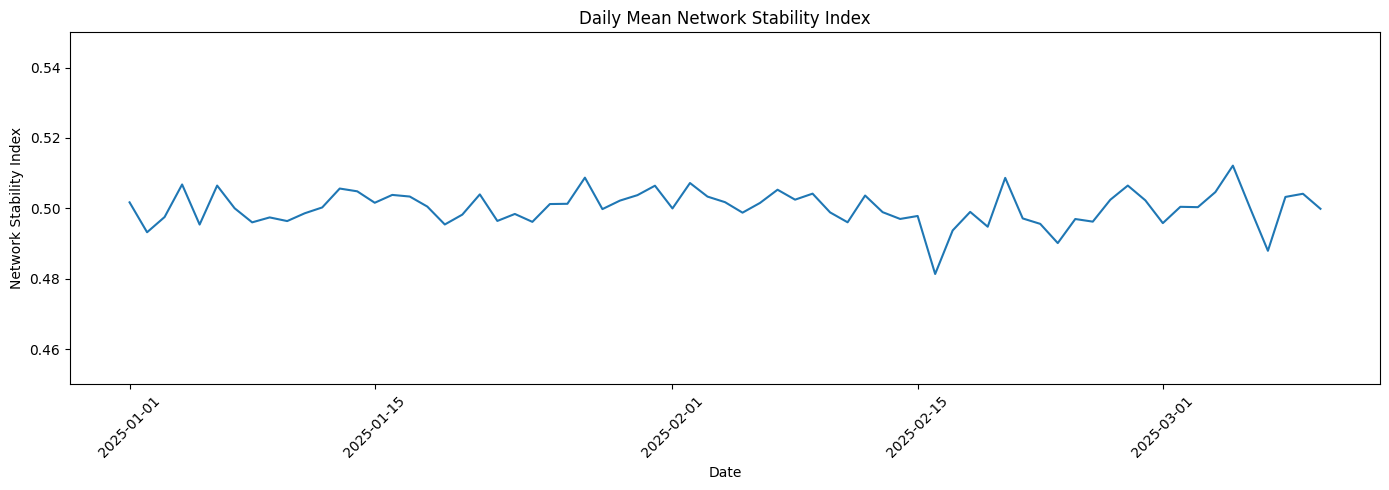

Saved: ..\Outputs\Figures\F02_Daily_Network_Stability_Index.png


In [101]:
plt.figure(figsize=(14, 5))

plt.plot(
    daily_network_profile.index,
    daily_network_profile['mean']
)

plt.title('Daily Mean Network Stability Index')
plt.xlabel('Date')
plt.ylabel('Network Stability Index')
plt.ylim(0.45, 0.55)
plt.xticks(rotation=45)
plt.tight_layout()

output_dir = Path("../Outputs/Figures")
output_dir.mkdir(parents=True, exist_ok=True)

figure_path = output_dir / "F02_Daily_Network_Stability_Index.png"
plt.savefig(figure_path, dpi=300, bbox_inches="tight")

plt.show()

print(f"Saved: {figure_path}")

### Stability Interpretation

The daily Network Stability Index remains closely centered around 0.50 across the observed dates, with only limited variation in daily mean network stability. This indicates that the dataset does not show clearly separated date-level periods of sustained network stability or instability.

Within-day variation in latency and packet loss is present, but these differences are interpreted descriptively because observations occur at irregular machine-level intervals rather than as a continuous real-time network stream.

Therefore, no distinct date-level stable or unstable network period is identified from the available data. The Network Stability Index is instead used to compare relative network conditions across individual observations in the subsequent network-quality analysis.

### Segment Network Quality Levels

To compare manufacturing outcomes under different network conditions, the Network Stability Index is divided into three dataset-relative quality levels: Low, Medium, and High.

These groups are created using tertiles, so they represent relative network conditions within this dataset rather than universal 6G engineering thresholds.

In [58]:
df_clean['Network_Stability_Index'].quantile(
    [0.10, 0.25, 0.50, 0.75, 0.90]
).round(3)

0.10    0.225
0.25    0.355
0.50    0.500
0.75    0.645
0.90    0.776
Name: Network_Stability_Index, dtype: float64

In [59]:
df_clean['Network_Stability_Index'].quantile(
    [1/3, 2/3]
).round(3)

0.333333    0.409
0.666667    0.591
Name: Network_Stability_Index, dtype: float64

### Network Quality Distribution

The proportion of observations assigned to each network-quality level is checked to confirm that the tertile segmentation produces the intended Low, Medium, and High groups.

In [60]:
df_clean['Network_Quality'].value_counts(
    normalize=True
).sort_index().mul(100).round(2)

Network_Quality
Low       33.33
Medium    33.33
High      33.33
Name: proportion, dtype: float64

In [61]:
df_clean.groupby('Network_Quality', observed=True)[
    ['Network_Latency_ms', 'Packet_Loss_%', 'Network_Stability_Index']
].agg(['mean', 'median', 'std']).round(3)

Network_Latency_ms                Packet_Loss_%                \
                              mean median     std          mean median    std   
Network_Quality                                                                 
Low                         36.628  38.26   9.479         3.630  3.796  0.972   
Medium                      25.626  25.65  13.142         2.489  2.487  1.343   
High                        14.413  12.85   9.427         1.361  1.195  0.964   

                Network_Stability_Index                
                                   mean median    std  
Network_Quality                                        
Low                               0.273  0.290  0.096  
Medium                            0.500  0.500  0.051  
High                              0.727  0.711  0.096

### Network Quality Interpretation

The three network-quality groups show progressively different observed network conditions. The Low-quality group has higher average latency and packet loss, while the High-quality group has lower average latency and packet loss. The Network Stability Index follows the same ordering, confirming that the segmentation is consistent with the underlying composite measure.

These categories therefore provide dataset-relative network conditions for comparing manufacturing outcomes in the subsequent analyses. They should not be interpreted as externally defined 6G performance standards.

### Network Quality Consistency Across Dates

The distribution of network-quality categories is checked across dates to verify that the tertile segmentation does not depend disproportionately on a small number of dates.

In [62]:
df_clean.groupby('Date')['Network_Quality'].value_counts(
    normalize=True
).unstack(fill_value=0).describe().round(3)

Network_Quality,Low,Medium,High
count,69.000,69.000,69.000
mean,0.333,0.333,0.333
std,0.013,0.012,0.011
min,0.305,0.310,0.303
25%,0.325,0.324,0.327
50%,0.333,0.331,0.334
75%,0.340,0.340,0.339
max,0.376,0.371,0.360


### Date-Level Segmentation Interpretation

The network-quality proportions remain broadly consistent across dates, with each category contributing approximately one-third of observations on average. This indicates that the tertile segmentation is not disproportionately driven by a small subset of dates.

The date-level variation is limited relative to the overall three-group structure, supporting the use of the network-quality categories for subsequent comparative analysis.

### Network Quality by Time of Day

The distribution of network-quality categories is also examined across clock time to determine whether particular times of day are systematically associated with one network-quality level.

This is a time-of-day comparison rather than a continuous chronological analysis.

In [63]:
df_clean.groupby('Timestamp')['Network_Quality'].value_counts(
    normalize=True
).unstack(fill_value=0).describe().round(3)

Network_Quality,Low,Medium,High
count,1440.000,1440.000,1440.000
mean,0.333,0.333,0.333
std,0.056,0.058,0.058
min,0.157,0.130,0.129
25%,0.290,0.290,0.290
50%,0.333,0.333,0.329
75%,0.371,0.371,0.371
max,0.529,0.522,0.529


### Time-of-Day Segmentation Interpretation

Across clock-time observations, all three network-quality categories remain represented throughout the observed timestamps. The category proportions vary somewhat at individual timestamps, but no single network-quality level consistently dominates the complete time-of-day profile.

This supports the use of the network-quality segmentation as a relative comparison of network conditions rather than as a category that is restricted to a particular clock-time period.

## Network vs Efficiency Analysis

### Analysis Objective

This section examines whether manufacturing efficiency indicators vary systematically across observed network-performance conditions.

The analysis focuses on:
- Comparing Efficiency_Status distributions across network-quality bands
- Examining efficiency-related performance across increasing latency ranges
- Identifying whether any sustained network-performance sensitivity zone is evident in the observed data

Production speed is used as a supporting continuous performance measure because Efficiency_Status is categorical.

All findings are descriptive and dataset-specific and are not interpreted as causal effects or universal network-performance thresholds.

### Compare Efficiency Status Across Network Quality Bands

This analysis compares the distribution of `Efficiency_Status` across the dataset-relative Low, Medium, and High network-quality bands.

The purpose is to determine whether the observed efficiency categories differ meaningfully under different levels of network stability.

In [109]:
efficiency_by_network_quality = (
    df_clean.groupby('Network_Quality', observed=True)
    .agg(
        Efficiency_Low=(
            'Efficiency_Status',
            lambda x: (x == 'Low').mean() * 100
        ),
        Efficiency_Medium=(
            'Efficiency_Status',
            lambda x: (x == 'Medium').mean() * 100
        ),
        Efficiency_High=(
            'Efficiency_Status',
            lambda x: (x == 'High').mean() * 100
        )
    )
    .round(2)
)

efficiency_by_network_quality

output_dir = Path("../Outputs/Tables")
output_dir.mkdir(parents=True, exist_ok=True)

table_path = output_dir / "T02_Network_Quality_vs_Efficiency.csv"
efficiency_by_network_quality.to_csv(table_path)

print(f"Saved: {table_path}")

Saved: ..\Outputs\Tables\T02_Network_Quality_vs_Efficiency.csv


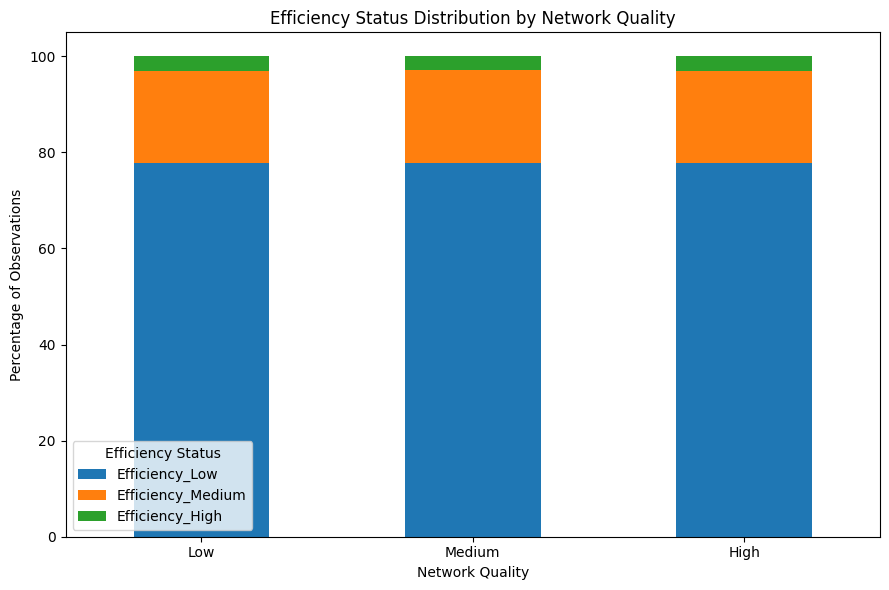

Saved: ..\Outputs\Figures\F03_Efficiency_by_Network_Quality.png


In [102]:
efficiency_by_network_quality.plot(
    kind='bar',
    stacked=True,
    figsize=(9, 6)
)

plt.title('Efficiency Status Distribution by Network Quality')
plt.xlabel('Network Quality')
plt.ylabel('Percentage of Observations')
plt.xticks(rotation=0)
plt.legend(title='Efficiency Status')
plt.tight_layout()

output_dir = Path("../Outputs/Figures")
output_dir.mkdir(parents=True, exist_ok=True)

figure_path = output_dir / "F03_Efficiency_by_Network_Quality.png"
plt.savefig(figure_path, dpi=300, bbox_inches="tight")

plt.show()

print(f"Saved: {figure_path}")

### Interpretation

The distribution of `Efficiency_Status` remains highly similar across the three network-quality bands. Low efficiency accounts for approximately 77.75%–77.89% of observations, representing a maximum difference of only 0.14 percentage points across the bands. Medium efficiency varies from approximately 19.08% to 19.33%, while High efficiency remains between approximately 2.92% and 3.03%.

Therefore, the categorical efficiency distribution does not show a substantial shift across the dataset-relative Low, Medium, and High network-quality categories. Within this analysis, network-quality segmentation is not associated with a pronounced change in `Efficiency_Status`.

These results are descriptive associations within the observed dataset and should not be interpreted as evidence that network quality causes or does not cause efficiency changes.

### Measure Efficiency Shifts with Increasing Latency

To examine whether efficiency changes progressively as network latency increases, observations are divided into ten equal-frequency latency groups (deciles).

Each decile represents approximately 10% of the observations, ordered from the lowest observed latency (D1) to the highest observed latency (D10). The distribution of `Efficiency_Status` is then compared across these latency levels.

This is a dataset-relative diagnostic. The deciles describe the observed latency distribution and should not be interpreted as externally defined engineering thresholds.

In [66]:
latency_deciles = pd.qcut(
    df_clean['Network_Latency_ms'],
    q=10,
    labels=[f'D{i}' for i in range(1, 11)]
)

efficiency_by_latency_decile = (
    df_clean.assign(Latency_Decile=latency_deciles)
    .groupby('Latency_Decile', observed=True)
    .agg(
        Efficiency_Low=(
            'Efficiency_Status',
            lambda x: (x == 'Low').mean() * 100
        ),
        Efficiency_Medium=(
            'Efficiency_Status',
            lambda x: (x == 'Medium').mean() * 100
        ),
        Efficiency_High=(
            'Efficiency_Status',
            lambda x: (x == 'High').mean() * 100
        )
    )
    .round(2)
)

efficiency_by_latency_decile

,Efficiency_Low,Efficiency_Medium,Efficiency_High
Latency_Decile,,,
D1,77.93,19.13,2.94
D2,77.98,19.00,3.02
D3,77.73,19.37,2.90
D4,77.35,19.51,3.14
D5,77.48,19.23,3.29
D6,78.49,18.54,2.97
D7,77.57,19.52,2.91
D8,77.65,19.24,3.11
D9,78.13,19.22,2.65


### Interpretation

The efficiency distribution remains broadly stable across the latency deciles. Low efficiency ranges from approximately 77.35% to 78.49%, a spread of 1.14 percentage points. Medium efficiency ranges from approximately 18.54% to 19.52%, while High efficiency ranges from approximately 2.65% to 3.29%.

Although individual deciles show small fluctuations, there is no sustained monotonic increase or decrease in any efficiency category as latency rises. In particular, the variation does not form a consistent directional pattern across successive latency deciles.

Therefore, `Efficiency_Status` alone does not identify a clear latency-sensitive efficiency zone in this dataset. Latency-related performance sensitivity is examined further using the continuous production-speed measure as a supporting operational-performance indicator.

These findings are descriptive associations within the observed data and do not establish a causal effect of latency on efficiency.

### Efficiency Distribution Across Latency Deciles

The following visualization compares the composition of `Efficiency_Status` across increasing latency deciles.

Because the three efficiency categories form the complete distribution within each decile, a 100% stacked bar chart is used to examine whether the composition changes systematically as latency increases.

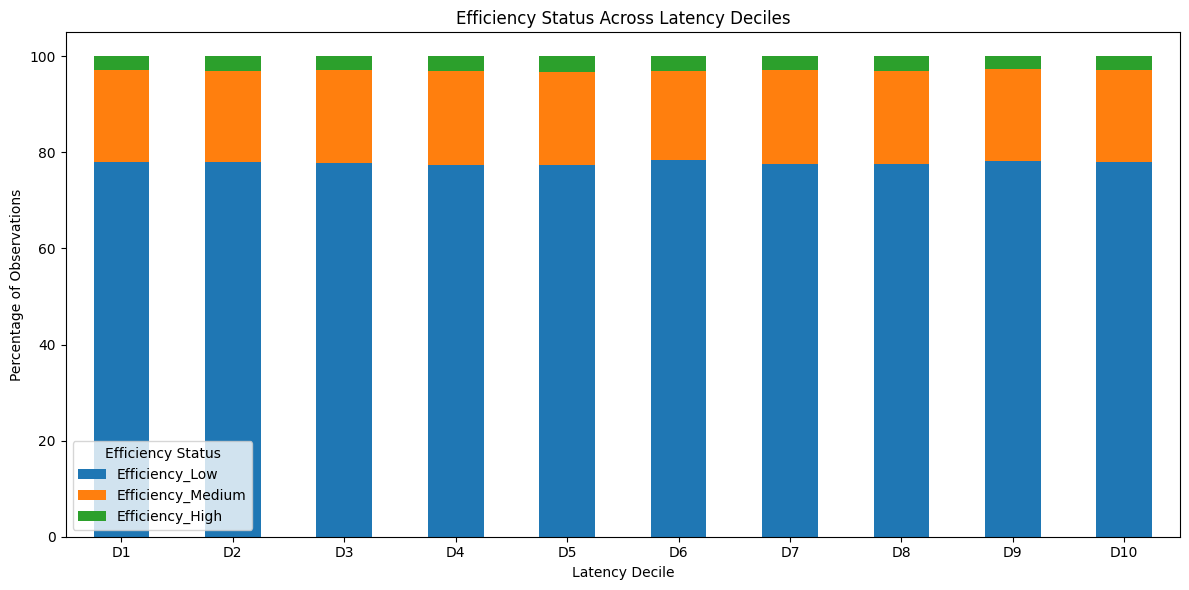

In [67]:
efficiency_by_latency_decile.plot(
    kind='bar',
    stacked=True,
    figsize=(12, 6)
)

plt.title('Efficiency Status Across Latency Deciles')
plt.xlabel('Latency Decile')
plt.ylabel('Percentage of Observations')
plt.xticks(rotation=0)
plt.legend(title='Efficiency Status')
plt.tight_layout()
plt.show()

### Interpretation

The stacked distribution remains visually similar across all ten latency deciles. The proportions of Low, Medium, and High efficiency do not show a sustained directional change as latency increases.

Therefore, within this dataset, the observed latency deciles do not show a clearly identifiable progressive shift in the categorical efficiency distribution.

The observed variation between individual deciles appears small relative to the overall distribution and does not provide sufficient evidence for defining a latency-sensitive efficiency zone from `Efficiency_Status` alone.

### Identify Performance Sensitivity Zones

A performance sensitivity zone is examined by looking for a sustained change in manufacturing performance as network latency increases.

Because the efficiency distribution across latency deciles remains broadly stable, this analysis also considers production speed to determine whether higher latency is associated with a consistent reduction in output performance.

The objective is to distinguish a sustained sensitivity pattern from isolated variation between individual latency ranges.

In [68]:
production_by_latency_decile = (
    df_clean.assign(Latency_Decile=latency_deciles)
    .groupby('Latency_Decile', observed=True)
    .agg(
        Production_Speed_Mean=('Production_Speed_units_per_hr', 'mean'),
        Production_Speed_Median=('Production_Speed_units_per_hr', 'median')
    )
    .round(2)
)

production_by_latency_decile

,Production_Speed_Mean,Production_Speed_Median
Latency_Decile,,
D1,275.11,275.63
D2,275.46,275.34
D3,276.24,276.67
D4,278.03,279.55
D5,278.52,281.84
D6,272.81,271.88
D7,274.36,274.86
D8,277.97,279.22
D9,276.09,276.26


### Interpretation

Mean production speed varies across the latency deciles, with the lowest observed value occurring in D6 at approximately 272.81 units/hr. However, this reduction does not persist as latency increases: production speed rises again in D7 to approximately 274.36 units/hr and in D8 to approximately 277.97 units/hr, followed by further variation across D9 and D10.

The D6 value therefore represents an isolated dip rather than a sustained deterioration across successive higher-latency ranges. The subsequent recovery prevents D6 from being classified as a clear latency-sensitive performance zone based on this analysis alone.

Overall, the production-speed pattern across latency deciles is non-monotonic. Consequently, the available data does not provide sufficient evidence for a distinct sustained latency threshold or sensitivity zone affecting operational performance.

Production speed is used here as a supporting continuous performance measure alongside the categorical `Efficiency_Status` analysis. The findings describe associations observed within this dataset and should not be interpreted as evidence of a causal latency effect or as a universal 6G engineering threshold.

## Latency Impact Diagnostics

### Analysis Objective

This section examines how network latency is associated with manufacturing output performance.

The analysis focuses on three questions:

1. Whether production speed shows a measurable relationship with network latency.
2. Whether higher latency ranges are associated with sustained output slowdowns.
3. Whether the available timestamp and observation-gap structure supports a meaningful comparison between real-time and delayed communication periods.

The analysis is descriptive and dataset-specific. Observed relationships are not interpreted as causal effects.

### Analyze Production Speed vs Latency

Production speed is compared directly with network latency to determine whether higher observed latency is associated with changes in manufacturing output.

A Spearman correlation is used because it evaluates the direction and strength of a monotonic relationship without requiring the relationship to be strictly linear.

In [69]:
latency_production_correlation = (
    df_clean[
        ['Network_Latency_ms', 'Production_Speed_units_per_hr']
    ]
    .corr(method='spearman')
    .iloc[0, 1]
)

round(latency_production_correlation, 4)

np.float64(-0.0011)

### Quantify the Observed Latency–Production Trend

The Spearman correlation indicates an extremely weak monotonic association between network latency and production speed.

To complement this result, a simple linear fit is used to quantify the observed direction and magnitude of the production-speed change across the latency range.

The fitted slope is descriptive and should not be interpreted as a causal effect of latency on production.

In [70]:
latency_slope, latency_intercept = np.polyfit(
    df_clean['Network_Latency_ms'],
    df_clean['Production_Speed_units_per_hr'],
    1
)

round(latency_slope, 6)

np.float64(-0.009671)

### Interpretation

The Spearman correlation between network latency and production speed is approximately -0.0011, indicating an extremely weak monotonic association in the observed data.

The fitted linear slope is approximately -0.009671 production units per hour for each 1 ms increase in latency. However, given the near-zero correlation, this fitted slope represents only a very small descriptive trend and does not indicate a meaningful latency-related production slowdown in the observed data.

Overall, the continuous latency analysis does not show a strong or consistent relationship between network latency and production speed.

### Production Speed vs Network Latency

The scatter plot below visualizes the observed relationship between network latency and production speed.

The fitted trend line is included as a descriptive reference to show the overall direction of the observed data.

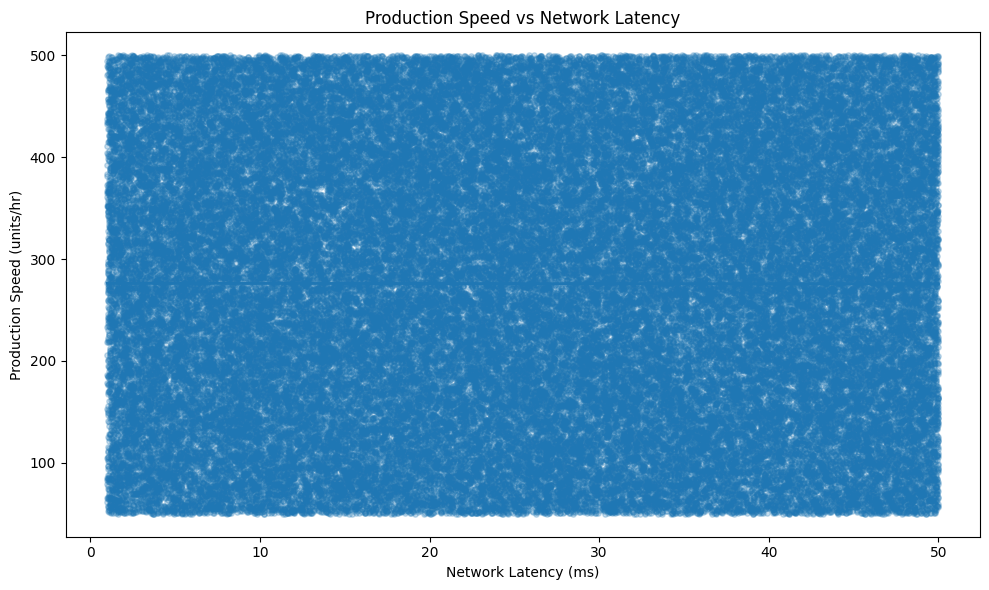

Saved: ..\Outputs\Figures\F04_Production_Speed_vs_Latency.png


In [103]:
plt.figure(figsize=(10, 6))

sns.regplot(
    data=df_clean,
    x='Network_Latency_ms',
    y='Production_Speed_units_per_hr',
    scatter_kws={'alpha': 0.25, 's': 15},
    line_kws={'linewidth': 2}
)

plt.title('Production Speed vs Network Latency')
plt.xlabel('Network Latency (ms)')
plt.ylabel('Production Speed (units/hr)')
plt.tight_layout()

output_dir = Path("../Outputs/Figures")
output_dir.mkdir(parents=True, exist_ok=True)

figure_path = output_dir / "F04_Production_Speed_vs_Latency.png"
plt.savefig(figure_path, dpi=300, bbox_inches="tight")

plt.show()

print(f"Saved: {figure_path}")

### Interpretation

The scatter plot shows a broad distribution of production speeds across the observed latency range, without a clear directional pattern.

The near-zero Spearman correlation (-0.0011) indicates an extremely weak monotonic association between network latency and production speed. The fitted trend line is also nearly flat, with a descriptive slope of approximately -0.009671 production units per hour per 1 ms increase in latency.

Taken together, these results do not show a strong or consistent relationship between network latency and production speed in the observed dataset.

This analysis describes the observed association and does not establish that latency has no effect under different operating or network conditions.

### Identify Latency Ranges Associated with Output Slowdowns

The latency deciles established earlier are used to examine whether particular ranges of observed latency are associated with lower production speed.

For each decile, the minimum and maximum observed latency are reported together with the mean and median production speed.

This provides a dataset-relative view of output variation across increasing latency ranges without imposing external engineering thresholds.

In [110]:
latency_range_production = (
    df_clean.assign(Latency_Decile=latency_deciles)
    .groupby('Latency_Decile', observed=True)
    .agg(
        Latency_Min_ms=('Network_Latency_ms', 'min'),
        Latency_Max_ms=('Network_Latency_ms', 'max'),
        Production_Speed_Mean=('Production_Speed_units_per_hr', 'mean'),
        Production_Speed_Median=('Production_Speed_units_per_hr', 'median')
    )
    .round(2)
)

latency_range_production

output_dir = Path("../Outputs/Tables")
output_dir.mkdir(parents=True, exist_ok=True)

table_path = output_dir / "T03_Latency_Decile_Performance.csv"
latency_range_production.to_csv(table_path)

print(f"Saved: {table_path}")

Saved: ..\Outputs\Tables\T03_Latency_Decile_Performance.csv


### Interpretation

Production speed varies across the observed latency ranges, but the variation does not follow a sustained downward pattern as latency increases.

The lowest mean and median production speeds occur in D6, corresponding to an observed latency range of approximately 25.54–30.42 ms. However, production speed increases again in D7 and D8, and the highest-latency range (D10: 45.13–50.00 ms) does not show the lowest output.

Therefore, D6 represents an observed lower-output range rather than a sustained latency-related slowdown zone. The results do not provide sufficient evidence to designate a specific latency range as an output slowdown threshold.

These findings are descriptive and do not establish that the observed reduction in D6 is caused by network latency.

### Production Speed Across Latency Ranges

The following visualization compares mean production speed across the observed latency deciles.

The purpose is to make the variation across latency ranges easier to assess and to determine whether the lower output observed in D6 represents a sustained pattern or an isolated deviation.

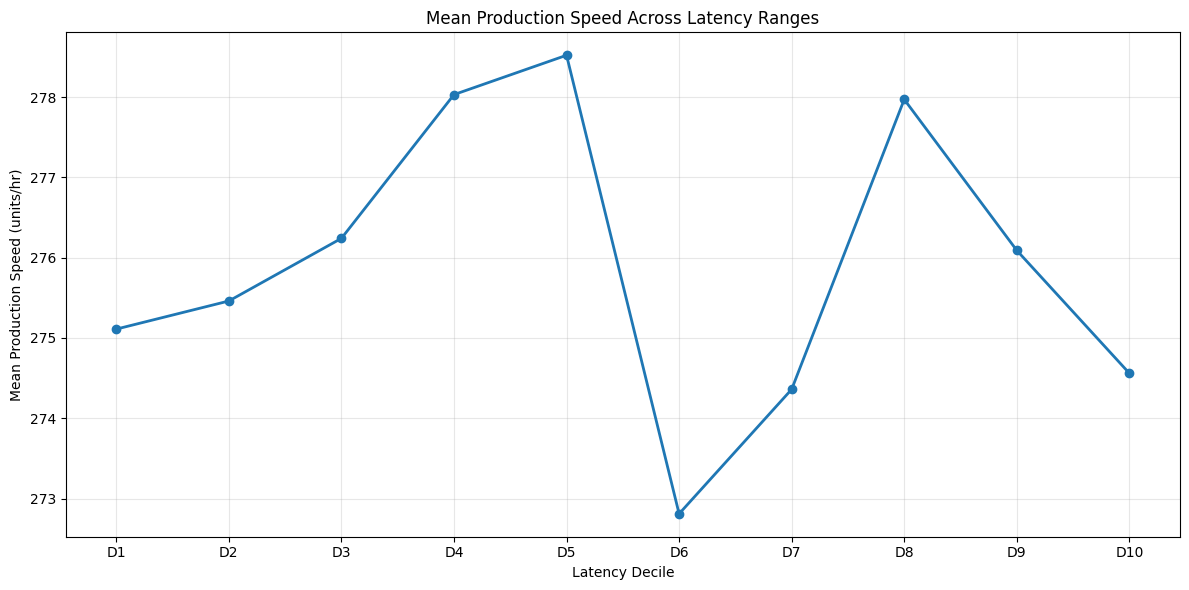

Saved: ..\Outputs\Figures\F05_Production_Speed_by_Latency_Decile.png


In [104]:
plt.figure(figsize=(12, 6))

plt.plot(
    latency_range_production.index,
    latency_range_production['Production_Speed_Mean'],
    marker='o',
    linewidth=2
)

plt.title('Mean Production Speed Across Latency Ranges')
plt.xlabel('Latency Decile')
plt.ylabel('Mean Production Speed (units/hr)')
plt.grid(True, alpha=0.3)
plt.tight_layout()

output_dir = Path("../Outputs/Figures")
output_dir.mkdir(parents=True, exist_ok=True)

figure_path = output_dir / "F05_Production_Speed_by_Latency_Decile.png"
plt.savefig(figure_path, dpi=300, bbox_inches="tight")

plt.show()

print(f"Saved: {figure_path}")

### Interpretation

The production-speed profile shows an increase from D1 through D5, followed by a pronounced dip in D6 and a recovery in D7 and D8. Production speed then decreases again in D9 and D10.

The D6 range (approximately 25.54–30.42 ms) has the lowest observed mean production speed, but the subsequent recovery at higher latency levels indicates that this reduction is not part of a sustained downward progression.

The highest-latency range, D10 (45.13–50.00 ms), also does not correspond to the lowest production output.

Therefore, the observed data does not support defining a specific latency range as a sustained output-slowdown threshold. D6 should be treated as an observed lower-output range requiring further investigation rather than as evidence of a latency threshold.

### Compare Real-Time vs Delayed Communication Periods

The dataset does not provide an explicit variable identifying communication as real-time or delayed.

Therefore, communication timing is examined using the observed time gap between consecutive observations for each machine. This diagnostic first establishes the distribution of machine-level observation gaps before defining any real-time or delayed communication categories.

Because the dataset contains irregular observation intervals and a known structural timestamp anomaly, time gaps are treated as an observational diagnostic rather than as direct measurements of communication delay.

In [74]:
df_time = (
    df_clean
    .sort_values(['Machine_ID', 'Datetime'])
    .copy()
)

time_gaps = (
    df_time
    .groupby('Machine_ID')['Datetime']
    .diff()
)

In [75]:
gap_minutes = time_gaps.dt.total_seconds() / 60

gap_summary = pd.Series({
    'Observation_Count': gap_minutes.count(),
    'Mean_Minutes': gap_minutes.mean(),
    'Std_Minutes': gap_minutes.std(),
    'Minimum_Minutes': gap_minutes.min(),
    'Q1_Minutes': gap_minutes.quantile(0.25),
    'Median_Minutes': gap_minutes.median(),
    'Q3_Minutes': gap_minutes.quantile(0.75),
    'Maximum_Minutes': gap_minutes.max()
}).round(2)

gap_summary

Observation_Count    99950.00
Mean_Minutes            49.25
Std_Minutes             48.89
Minimum_Minutes          0.00
Q1_Minutes              14.00
Median_Minutes          34.00
Q3_Minutes              68.00
Maximum_Minutes        514.00
dtype: float64

In [76]:
zero_gap_count = (gap_minutes == 0).sum()
zero_gap_percentage = (gap_minutes == 0).mean() * 100

pd.Series({
    'Zero_Gap_Count': zero_gap_count,
    'Zero_Gap_Percentage': zero_gap_percentage
}).round(2)

Zero_Gap_Count         28.00
Zero_Gap_Percentage     0.03
dtype: float64

### Defining Observation-Gap Proxies

The dataset does not contain an explicit indicator of real-time or delayed communication. Therefore, communication timing cannot be classified directly from the available variables.

As a descriptive proxy, the shortest and longest observation-gap groups are compared. The short-gap group contains observations at or below the 25th percentile of the machine-level observation-gap distribution (≤14 minutes), while the long-gap group contains observations at or above the 75th percentile (≥68 minutes).

These groups represent shorter and longer observation intervals rather than measured real-time and delayed communication states. The middle 50% of observation gaps is excluded from this comparison.

Accordingly, this comparison is used only to assess whether shorter versus longer observation intervals coincide with different manufacturing outcomes; it is not used to infer a network communication-delay threshold.

In [77]:
short_gap_threshold = gap_minutes.quantile(0.25)
long_gap_threshold = gap_minutes.quantile(0.75)

short_gap_threshold, long_gap_threshold

(np.float64(14.0), np.float64(68.0))

### Compare Short and Long Observation-Gap Periods

The observation-gap thresholds derived from the machine-level gap distribution are applied to the dataset.

Observations with a gap at or below the 25th percentile (≤14 minutes) are classified as the Short Gap proxy group, while observations at or above the 75th percentile (≥68 minutes) are classified as the Long Gap proxy group. The middle 50% of observation gaps is excluded.

The comparison examines production speed, network latency, packet loss, and efficiency status across these two groups.

These groups represent shorter and longer observation intervals rather than measured real-time and delayed communication states. Therefore, the comparison is interpreted as an observation-gap diagnostic rather than a direct test of communication-delay effects.

In [78]:
df_time['Observation_Gap_Minutes'] = (
    df_time.groupby('Machine_ID')['Datetime']
    .diff()
    .dt.total_seconds()
    .div(60)
)

df_time['Observation_Gap_Group'] = np.select(
    [
        df_time['Observation_Gap_Minutes'] <= short_gap_threshold,
        df_time['Observation_Gap_Minutes'] >= long_gap_threshold
    ],
    [
        'Short Gap',
        'Long Gap'
    ],
    default='Middle Gap'
)

gap_comparison = (
    df_time[df_time['Observation_Gap_Group'].isin(['Short Gap', 'Long Gap'])]
    .groupby('Observation_Gap_Group')
    .agg(
        Observation_Count=('Machine_ID', 'size'),
        Production_Speed_Mean=('Production_Speed_units_per_hr', 'mean'),
        Production_Speed_Median=('Production_Speed_units_per_hr', 'median'),
        Latency_Mean_ms=('Network_Latency_ms', 'mean'),
        Packet_Loss_Mean_pct=('Packet_Loss_%', 'mean')
    )
    .round(2)
)

gap_comparison

,Observation_Count,Production_Speed_Mean,Production_Speed_Median,Latency_Mean_ms,Packet_Loss_Mean_pct
Observation_Gap_Group,,,,,
Long Gap,25269,275.14,275.17,25.48,2.49
Short Gap,25065,275.39,276.13,25.56,2.50


In [79]:
efficiency_by_gap_group = (
    df_time[
        df_time['Observation_Gap_Group'].isin(['Short Gap', 'Long Gap'])
    ]
    .groupby('Observation_Gap_Group', observed=True)
    .agg(
        Efficiency_Low=(
            'Efficiency_Status',
            lambda x: (x == 'Low').mean() * 100
        ),
        Efficiency_Medium=(
            'Efficiency_Status',
            lambda x: (x == 'Medium').mean() * 100
        ),
        Efficiency_High=(
            'Efficiency_Status',
            lambda x: (x == 'High').mean() * 100
        )
    )
    .round(2)
)

efficiency_by_gap_group

,Efficiency_Low,Efficiency_Medium,Efficiency_High
Observation_Gap_Group,,,
Long Gap,77.57,19.32,3.11
Short Gap,78.02,18.97,3.01


### Interpretation

The comparison between shorter and longer observation-gap proxy groups shows very similar manufacturing and network characteristics.

Mean production speed is 275.39 units/hr for the Short Gap group and 275.14 units/hr for the Long Gap group, a difference of only 0.25 units/hr. Mean network latency and packet loss are also very similar between the two groups.

The `Efficiency_Status` distribution remains broadly stable, with Low efficiency accounting for 78.02% of Short Gap observations and 77.57% of Long Gap observations. Medium and High efficiency also show only small differences.

Therefore, the available observation-gap proxy does not show a clear difference in production performance, network conditions, or efficiency distribution between shorter and longer observation intervals.

Because observation gaps are not direct measurements of communication delay, these results cannot be interpreted as evidence that real-time and delayed communication have equivalent operational effects. The dataset does not contain an explicit communication-delay variable, so no direct real-time versus delayed communication effect can be established from the available data.

### Efficiency Distribution Across Observation-Gap Groups

The following visualization compares the distribution of `Efficiency_Status` between the shorter and longer observation-gap proxy groups.

The comparison is presented as percentages because the three efficiency categories form the complete composition within each group.

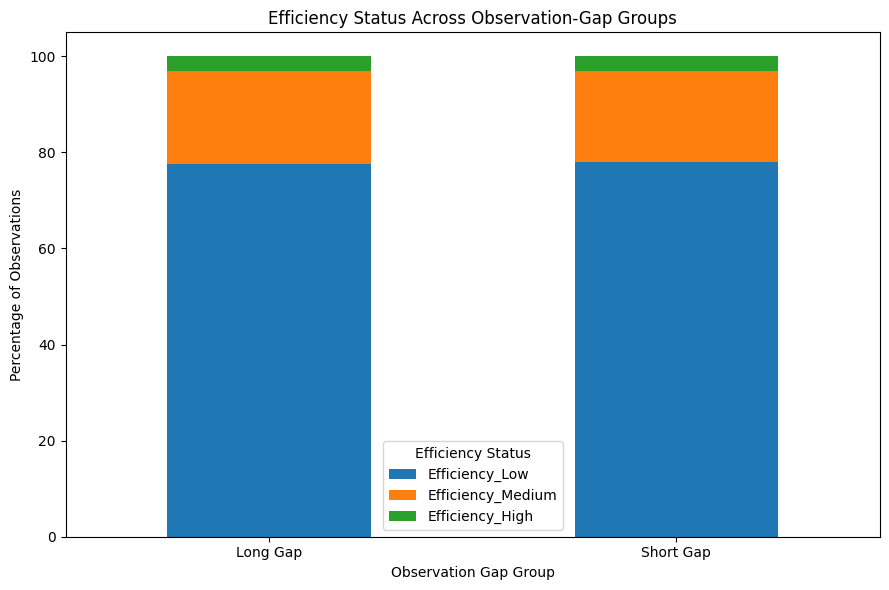

In [80]:
efficiency_by_gap_group.plot(
    kind='bar',
    stacked=True,
    figsize=(9, 6)
)

plt.title('Efficiency Status Across Observation-Gap Groups')
plt.xlabel('Observation Gap Group')
plt.ylabel('Percentage of Observations')
plt.xticks(rotation=0)
plt.legend(title='Efficiency Status')
plt.tight_layout()
plt.show()

### Interpretation

The efficiency distribution is broadly similar across the Short Gap and Long Gap proxy groups.

The proportion of Low efficiency observations is 78.02% for the Short Gap group and 77.57% for the Long Gap group. Medium efficiency accounts for 18.97% and 19.32%, while High efficiency accounts for 3.01% and 3.11%, respectively.

The small differences between the two groups do not indicate a clear change in efficiency distribution associated with shorter versus longer observation intervals.

Because these groups represent observation gaps rather than measured communication delays, this comparison does not establish a direct difference between real-time and delayed communication performance and cannot be used to define a communication-delay threshold.

## Packet Loss Impact Diagnostics

### Analysis Objective

This section examines whether packet loss is associated with manufacturing error, defect, and operational-performance indicators.

The analysis focuses on three questions:

1. Whether packet loss shows a measurable relationship with error rate.
2. Whether defect rate changes across progressively higher packet-loss ranges.
3. Whether the observed packet-loss distribution shows a consistent deterioration in manufacturing performance that could support identifying a dataset-relative communication reliability range.

The analysis is descriptive and dataset-specific. Observed relationships are not interpreted as causal effects, and no external communication-reliability threshold is imposed.

### Correlate Packet Loss with Error Rate

A Spearman correlation is used to examine the direction and strength of the monotonic association between packet loss and error rate.

This provides a continuous measure of whether higher observed packet loss tends to coincide with higher or lower error rates in the dataset.

In [81]:
packet_loss_error_correlation = (
    df_clean[
        ['Packet_Loss_%', 'Error_Rate_%']
    ]
    .corr(method='spearman')
    .iloc[0, 1]
)

round(packet_loss_error_correlation, 4)

np.float64(-0.0024)

### Interpretation

The Spearman correlation between packet loss and error rate is approximately -0.0024, indicating an extremely weak monotonic association in the observed data.

The correlation is close to zero and does not show a meaningful directional relationship between increasing packet loss and error rate across the full dataset.

Therefore, the continuous packet-loss analysis does not provide evidence of a strong or consistent association between packet loss and error rate in the observed data.

This result describes the overall observed relationship and does not establish that packet loss has no effect under specific network or operating conditions.

### Error Rate vs Packet Loss

The scatter plot below visualizes the observed relationship between packet loss and error rate.

The plot is used to assess whether the near-zero correlation reflects a broadly patternless distribution or whether localized patterns may be present despite the weak overall association.

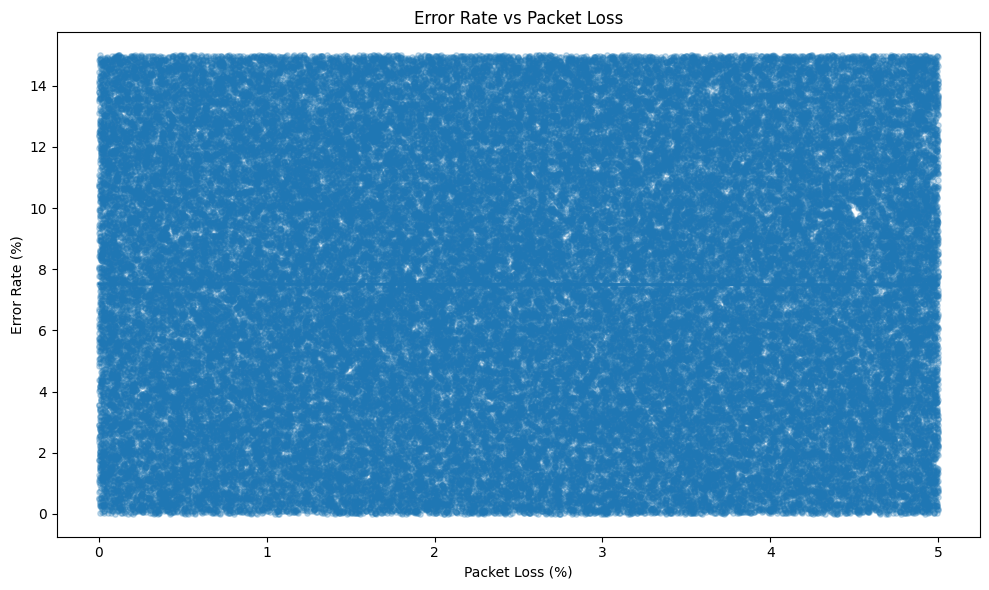

Saved: ..\Outputs\Figures\F06_Error_Rate_vs_Packet_Loss.png


In [105]:
plt.figure(figsize=(10, 6))

sns.regplot(
    data=df_clean,
    x='Packet_Loss_%',
    y='Error_Rate_%',
    scatter_kws={'alpha': 0.25, 's': 15},
    line_kws={'linewidth': 2}
)

plt.title('Error Rate vs Packet Loss')
plt.xlabel('Packet Loss (%)')
plt.ylabel('Error Rate (%)')
plt.tight_layout()

output_dir = Path("../Outputs/Figures")
output_dir.mkdir(parents=True, exist_ok=True)

figure_path = output_dir / "F06_Error_Rate_vs_Packet_Loss.png"
plt.savefig(figure_path, dpi=300, bbox_inches="tight")

plt.show()

print(f"Saved: {figure_path}")

### Interpretation

The scatter plot shows a broad distribution of error rates across the observed packet-loss range, without a clear directional pattern.

The near-zero Spearman correlation (-0.0024) indicates an extremely weak monotonic association between packet loss and error rate. The fitted trend line is also nearly flat, providing no indication of a strong overall increase in error rate as packet loss increases.

Taken together, the continuous packet-loss analysis does not show a strong or consistent relationship between packet loss and error rate in the observed dataset.

This analysis describes the overall observed association and does not establish that packet loss has no effect under specific network or operating conditions.

### Assess Defect Rate During Packet Loss Spikes

Packet-loss deciles are used to examine whether defect rates change across progressively higher ranges of observed packet loss.

The analysis compares the observed packet-loss range with the mean and median defect rate within each decile. This provides a dataset-relative view of defect-rate variation during higher packet-loss conditions without imposing an external communication threshold.

In [83]:
packet_loss_deciles = pd.qcut(
    df_clean['Packet_Loss_%'],
    q=10,
    labels=[f'D{i}' for i in range(1, 11)]
)

packet_loss_defect = (
    df_clean.assign(Packet_Loss_Decile=packet_loss_deciles)
    .groupby('Packet_Loss_Decile', observed=True)
    .agg(
        Packet_Loss_Min_pct=('Packet_Loss_%', 'min'),
        Packet_Loss_Max_pct=('Packet_Loss_%', 'max'),
        Defect_Rate_Mean=('Quality_Control_Defect_Rate_%', 'mean'),
        Defect_Rate_Median=('Quality_Control_Defect_Rate_%', 'median')
    )
    .round(2)
)

packet_loss_defect

,Packet_Loss_Min_pct,Packet_Loss_Max_pct,Defect_Rate_Mean,Defect_Rate_Median
Packet_Loss_Decile,,,,
D1,0.00,0.50,5.02,5.00
D2,0.50,1.00,5.07,5.12
D3,1.00,1.50,5.04,5.06
D4,1.50,1.99,5.01,5.01
D5,1.99,2.49,5.00,5.02
D6,2.49,2.99,4.98,4.94
D7,2.99,3.49,4.95,4.95
D8,3.49,3.99,4.98,4.94
D9,3.99,4.50,5.03,5.02


### Interpretation

Defect rates remain highly stable across the observed packet-loss deciles.

The mean defect rate ranges from approximately 4.95% to 5.07% across D1–D10, a total spread of only 0.12 percentage points. Median defect rates remain similarly close to 5%, and there is no sustained increase as packet loss moves toward the higher observed ranges.

The highest packet-loss decile (D10: 4.50–5.00%) has a mean defect rate of 5.01%, which is very close to the values observed in the lower packet-loss deciles.

Therefore, the observed packet-loss ranges do not show a clear defect-rate increase or a sustained packet-loss-related defect spike in this dataset. No specific packet-loss range is designated as a defect-rate threshold based on this analysis alone.

These findings describe observed associations within the dataset and should not be interpreted as evidence that packet loss has no effect under specific network or operating conditions.

### Defect Rate Across Packet-Loss Ranges

The following visualization compares mean defect rate across the observed packet-loss deciles.

The purpose is to assess whether defect rates show a sustained increase as packet loss moves toward the higher observed ranges.

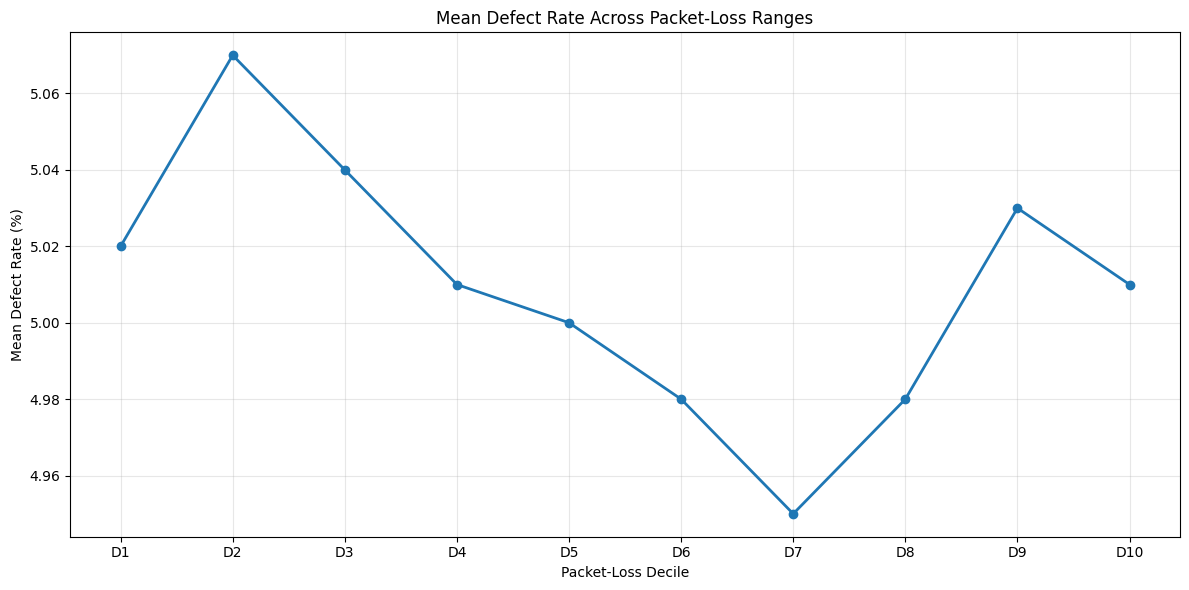

Saved: ..\Outputs\Figures\F07_Defect_Rate_by_Packet_Loss_Range.png


In [106]:
plt.figure(figsize=(12, 6))

plt.plot(
    packet_loss_defect.index,
    packet_loss_defect['Defect_Rate_Mean'],
    marker='o',
    linewidth=2
)

plt.title('Mean Defect Rate Across Packet-Loss Ranges')
plt.xlabel('Packet-Loss Decile')
plt.ylabel('Mean Defect Rate (%)')
plt.grid(True, alpha=0.3)
plt.tight_layout()

output_dir = Path("../Outputs/Figures")
output_dir.mkdir(parents=True, exist_ok=True)

figure_path = output_dir / "F07_Defect_Rate_by_Packet_Loss_Range.png"
plt.savefig(figure_path, dpi=300, bbox_inches="tight")

plt.show()

print(f"Saved: {figure_path}")

### Identify Communication Reliability Ranges

The observed packet-loss distribution is examined to determine whether higher packet-loss ranges correspond to a consistent deterioration in manufacturing performance indicators.

Because the dataset does not provide an explicit communication-reliability threshold, no external engineering cutoff is imposed. Instead, packet-loss deciles are used to identify whether the observed error rate, defect rate, production speed, or efficiency distribution changes consistently toward higher packet-loss ranges.

Any resulting range is therefore interpreted as a dataset-relative analytical observation rather than a universal communication reliability threshold.

In [111]:
packet_loss_reliability_summary = (
    df_clean.assign(Packet_Loss_Decile=packet_loss_deciles)
    .groupby('Packet_Loss_Decile', observed=True)
    .agg(
        Packet_Loss_Min_pct=('Packet_Loss_%', 'min'),
        Packet_Loss_Max_pct=('Packet_Loss_%', 'max'),
        Production_Speed_Mean=('Production_Speed_units_per_hr', 'mean'),
        Error_Rate_Mean=('Error_Rate_%', 'mean'),
        Defect_Rate_Mean=('Quality_Control_Defect_Rate_%', 'mean')
    )
    .round(2)
)

packet_loss_reliability_summary

output_dir = Path("../Outputs/Tables")
output_dir.mkdir(parents=True, exist_ok=True)

table_path = output_dir / "T04_Packet_Loss_Reliability.csv"
packet_loss_reliability_summary.to_csv(table_path)

print(f"Saved: {table_path}")

Saved: ..\Outputs\Tables\T04_Packet_Loss_Reliability.csv


### Interpretation

The packet-loss reliability summary does not show a consistent deterioration in manufacturing performance as packet loss increases.

Production speed varies across the packet-loss deciles, with the lowest mean observed in D10 (4.50–5.00%) at approximately 273.81 units/hr. However, lower production values also occur in intermediate ranges such as D6, and the pattern does not show a sustained decline across progressively higher packet-loss levels.

Error rate remains highly stable across all deciles, ranging from approximately 7.47% to 7.56%. Defect rate is similarly stable, ranging from approximately 4.95% to 5.07%.

Therefore, the observed packet-loss ranges do not provide sufficient evidence for identifying a distinct communication-reliability threshold or risk zone from these manufacturing indicators alone.

The highest observed packet-loss range of 4.50–5.00% should not be interpreted as a universal reliability limit. It represents only the upper observed range in this dataset. Further engineering validation would be required before establishing an operational communication-reliability threshold.

## Operation Mode Interaction Analysis

### Analysis Objective

This section examines whether the relationship between network conditions and manufacturing performance differs across machine operation modes.

The analysis focuses on three questions:

1. Whether network performance and manufacturing outcomes vary across operation modes.

2. Whether any operation mode shows greater sensitivity to increasing network latency, using production speed as a supporting operational-performance measure.

3. Whether efficiency distributions remain stable when operation modes are compared under similar mechanical conditions.

The analysis is descriptive and dataset-specific. Observed differences are not interpreted as causal effects.

### Evaluate Network Impact Across Operation Modes

Network and manufacturing performance indicators are compared across the observed operation modes.

The comparison includes network latency and packet loss together with production speed, error rate, and defect rate to determine whether the operating mode is associated with different observed network or manufacturing conditions.

In [112]:
operation_mode_summary = (
    df_clean
    .groupby('Operation_Mode')
    .agg(
        Observation_Count=('Machine_ID', 'size'),
        Latency_Mean_ms=('Network_Latency_ms', 'mean'),
        Packet_Loss_Mean_pct=('Packet_Loss_%', 'mean'),
        Production_Speed_Mean=('Production_Speed_units_per_hr', 'mean'),
        Error_Rate_Mean=('Error_Rate_%', 'mean'),
        Defect_Rate_Mean=('Quality_Control_Defect_Rate_%', 'mean')
    )
    .round(2)
)

operation_mode_summary

output_dir = Path("../Outputs/Tables")
output_dir.mkdir(parents=True, exist_ok=True)

table_path = output_dir / "T05_Operation_Mode_Summary.csv"
operation_mode_summary.to_csv(table_path)

print(f"Saved: {table_path}")

Saved: ..\Outputs\Tables\T05_Operation_Mode_Summary.csv


### Interpretation

The observed network conditions are broadly similar across the three operation modes. Mean latency ranges from approximately 25.50 to 25.64 ms, while mean packet loss ranges from approximately 2.48% to 2.50%.

Manufacturing indicators show somewhat greater variation across operation modes. Mean production speed is approximately 276.20 units/hr for Active, 274.13 units/hr for Idle, and 277.54 units/hr for Maintenance. Mean error and defect rates remain relatively close across the three modes.

Therefore, the operation modes do not show substantial differences in their overall observed network conditions. The variation in production speed across modes should consequently not be attributed to network conditions from this comparison alone.

A more detailed interaction analysis is required to determine whether the relationship between latency and manufacturing performance differs within individual operation modes.

### Identify Operation Modes Sensitive to Communication Delays

To examine whether operation modes respond differently to network latency, production speed is compared across latency deciles within each operation mode.

The analysis focuses on whether any operation mode shows a more consistent change in production speed as latency increases. Latency deciles are used as dataset-relative ranges rather than external communication thresholds.

Because the analysis is observational, any differences are interpreted as associations rather than causal effects.

In [87]:
operation_mode_latency_analysis = (
    df_clean
    .assign(
        Latency_Decile=pd.qcut(
            df_clean['Network_Latency_ms'],
            q=10,
            labels=[f'D{i}' for i in range(1, 11)]
        )
    )
    .groupby(
        ['Operation_Mode', 'Latency_Decile'],
        observed=True
    )
    .agg(
        Observation_Count=('Machine_ID', 'size'),
        Latency_Mean_ms=('Network_Latency_ms', 'mean'),
        Production_Speed_Mean=('Production_Speed_units_per_hr', 'mean'),
        Production_Speed_Median=('Production_Speed_units_per_hr', 'median')
    )
    .round(2)
)

operation_mode_latency_analysis

Observation_Count  Latency_Mean_ms  \
Operation_Mode Latency_Decile                                       
Active         D1                           6978             3.49   
               D2                           7045             8.46   
               D3                           7038            13.34   
               D4                           6961            18.29   
               D5                           6991            23.11   
               D6                           7036            27.96   
               D7                           7030            32.83   
               D8                           7049            37.79   
               D9                           6969            42.69   
               D10                          6957            47.57   
Idle           D1                           1988             3.50   
               D2                           1994             8.45   
               D3                           2015            13.39   
               D4                           2040            18.23   
               D5                           1997            23.13   
               D6                           1929            27.99   
               D7                           2021            32.90   
               D8                           1977            37.78   
               D9                           2040            42.68   
               D10                          2056            47.60   
Maintenance    D1                           1035             3.53   
               D2                            961             8.44   
               D3                            950            13.36   
               D4                            995            18.26   
               D5                           1014            23.12   
               D6                           1033            27.99   
               D7                            950            32.84   
               D8                            974            37.81   
               D9                            990            42.67   
               D10                           987            47.56   

                               Production_Speed_Mean  Production_Speed_Median  
Operation_Mode Latency_Decile                                                  
Active         D1                             275.07                   274.53  
               D2                             273.60                   270.84  
               D3                             275.68                   276.54  
               D4                             279.20                   282.14  
               D5                             280.71                   284.70  
               D6                             272.88                   271.54  
               D7                             275.85                   277.26  
               D8                             278.01                   277.90  
               D9                             275.79                   276.25  
               D10                            275.23                   276.74  
Idle           D1                             273.91                   274.35  
               D2                             280.39                   282.59  
               D3                             276.99                   275.66  
               D4                             275.49                   276.19  
               D5                             273.21                   273.70  
               D6                             269.91                   269.65  
               D7                             270.62                   268.53  
               D8                             275.63                   279.14  
               D9                             276.23                   276.61  
               D10                            268.86                   267.31  
Maintenance    D1                             277.67          

### Production Speed Across Latency Deciles by Operation Mode

The interaction between operation mode and latency is visualized by comparing mean production speed across latency deciles.

This visualization is used to identify whether any operation mode exhibits a sustained directional change in production speed as observed latency increases.

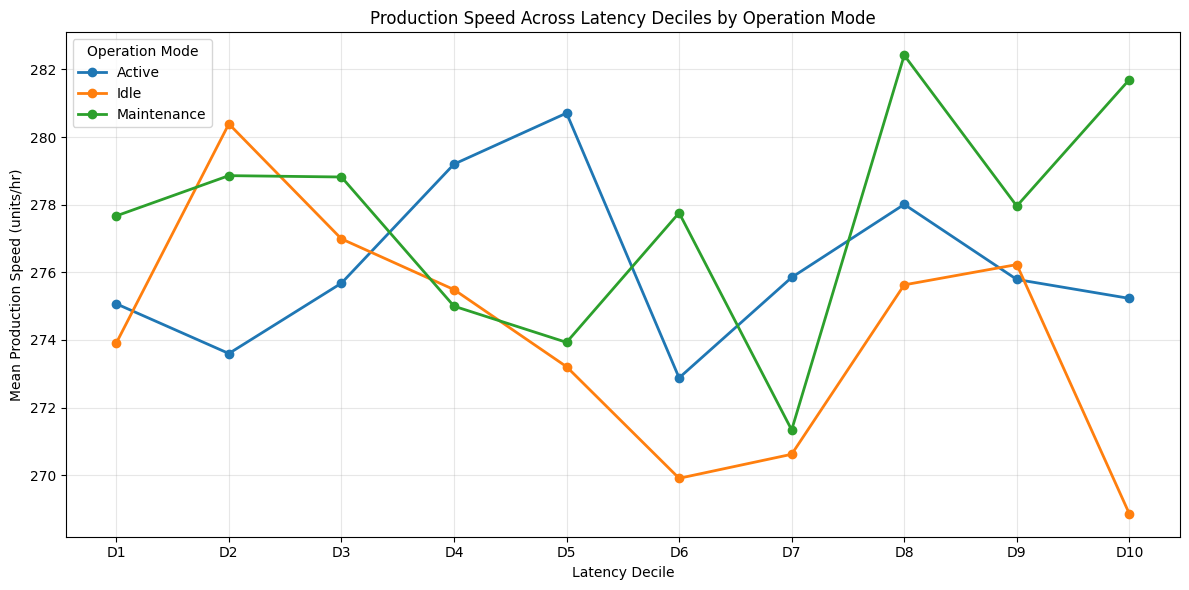

Saved: ..\Outputs\Figures\F08_Production_Speed_by_Latency_and_Operation_Mode.png


In [107]:
plt.figure(figsize=(12, 6))

for mode in operation_mode_latency_analysis.index.get_level_values(
    'Operation_Mode'
).unique():

    mode_data = operation_mode_latency_analysis.loc[mode]

    plt.plot(
        mode_data.index,
        mode_data['Production_Speed_Mean'],
        marker='o',
        linewidth=2,
        label=mode
    )

plt.title('Production Speed Across Latency Deciles by Operation Mode')
plt.xlabel('Latency Decile')
plt.ylabel('Mean Production Speed (units/hr)')
plt.legend(title='Operation Mode')
plt.grid(True, alpha=0.3)
plt.tight_layout()

output_dir = Path("../Outputs/Figures")
output_dir.mkdir(parents=True, exist_ok=True)

figure_path = output_dir / "F08_Production_Speed_by_Latency_and_Operation_Mode.png"
plt.savefig(figure_path, dpi=300, bbox_inches="tight")

plt.show()

print(f"Saved: {figure_path}")

### Interpretation

Production speed varies across latency deciles within all three operation modes, but none of the modes shows a sustained monotonic decline as latency increases.

For Active operation, production speed increases through the middle latency ranges, followed by a reduction around D6 and subsequent recovery. Idle operation shows several fluctuations, including lower production in D6, D7, and D10, while Maintenance operation also shows alternating increases and decreases across the latency deciles.

The fluctuations therefore do not form a consistent pattern in which increasing latency is accompanied by progressively lower production within a specific operation mode.

Based on the observed data, no operation mode can be identified as having a clearly defined latency-sensitive production zone from this analysis alone. The observed differences may reflect variation within the operation modes rather than a consistent association with latency.

This analysis is descriptive and does not establish a causal effect of communication delay on production performance.

### Compare Efficiency Stability Under Similar Mechanical Conditions

To reduce the influence of mechanical operating differences, temperature, vibration, and power consumption are divided into dataset-relative quartile bands.

These bands are used only to construct comparable mechanical-condition groups within the observed dataset. They do not represent external engineering limits or machine-health thresholds.

Efficiency distributions are then compared across network quality levels within these similar mechanical conditions.

In [89]:
mechanical_df = df_clean.copy()

mechanical_df['Temperature_Band'] = pd.qcut(
    mechanical_df['Temperature_C'],
    q=4,
    labels=['Low', 'Medium-Low', 'Medium-High', 'High']
)

mechanical_df['Vibration_Band'] = pd.qcut(
    mechanical_df['Vibration_Hz'],
    q=4,
    labels=['Low', 'Medium-Low', 'Medium-High', 'High']
)

mechanical_df['Power_Band'] = pd.qcut(
    mechanical_df['Power_Consumption_kW'],
    q=4,
    labels=['Low', 'Medium-Low', 'Medium-High', 'High']
)

mechanical_df[
    [
        'Temperature_Band',
        'Vibration_Band',
        'Power_Band'
    ]
].head()

,Temperature_Band,Vibration_Band,Power_Band
0,Medium-High,Medium-High,High
1,High,Medium-High,Low
2,Low,Medium-Low,Medium-High
3,Low,Low,Medium-Low
4,High,Low,Medium-High


### Constructing Comparable Mechanical Conditions

The three mechanical bands are combined to form a dataset-relative mechanical condition profile.

Each profile represents a combination of the observed temperature, vibration, and power-consumption ranges. These profiles are used to compare efficiency distributions under similar mechanical conditions while varying network quality.

The resulting profiles are descriptive groupings and should not be interpreted as machine-health classifications.

In [90]:
mechanical_df['Mechanical_Condition'] = (
    mechanical_df['Temperature_Band'].astype(str)
    + ' | '
    + mechanical_df['Vibration_Band'].astype(str)
    + ' | '
    + mechanical_df['Power_Band'].astype(str)
)

mechanical_df['Mechanical_Condition'].value_counts().head(10)

Mechanical_Condition
Medium-Low | Medium-High | High            1640
Low | Medium-Low | Medium-Low              1632
Low | High | Low                           1624
High | High | Medium-High                  1621
Medium-High | Low | Medium-Low             1617
Low | Low | Low                            1610
High | Medium-High | High                  1609
Medium-High | Medium-High | Medium-High    1604
Low | Low | Medium-Low                     1602
Medium-High | High | High                  1601
Name: count, dtype: int64

### Validate Mechanical-Condition Group Sizes

Before comparing efficiency across network-quality levels, the distribution of observations across mechanical-condition profiles is checked.

Only sufficiently represented profiles should be used for detailed comparisons so that conclusions are not driven by very small groups.

In [91]:
mechanical_condition_counts = (
    mechanical_df['Mechanical_Condition']
    .value_counts()
    .sort_values()
)

mechanical_condition_counts.describe().round(2)

count      64.00
mean     1562.50
std        34.41
min      1492.00
25%      1536.25
50%      1560.00
75%      1585.25
max      1640.00
Name: count, dtype: float64

### Profile Size Validation

The 64 mechanical-condition profiles contain substantial numbers of observations. Profile sizes range from approximately 1,492 to 1,640 observations, with an average of approximately 1,562 observations per profile.

The relatively similar profile sizes indicate that the mechanical-condition grouping does not create sparsely populated profiles in the observed dataset. Therefore, the subsequent within-profile comparison is not driven by a small number of observations in isolated profiles.

No arbitrary minimum sample-size threshold is imposed because the observed profile sizes are already well represented.

### Efficiency Distribution Within Comparable Mechanical Conditions

Efficiency stability is compared across network-quality levels within each observed mechanical-condition profile.

The profile-size validation shows that the 64 mechanical-condition profiles are reasonably represented in the observed dataset. Therefore, the comparison can be performed across the observed profiles without excluding groups solely because of sparse representation.

The analysis examines whether the distribution of Low, Medium, and High efficiency changes consistently with network quality when temperature, vibration, and power-consumption ranges are held within comparable dataset-relative profiles.

In [92]:
mechanical_network_efficiency = (
    mechanical_df
    .groupby(
        [
            'Mechanical_Condition',
            'Network_Quality',
            'Efficiency_Status'
        ],
        observed=True
    )
    .size()
    .groupby(
        level=[
            'Mechanical_Condition',
            'Network_Quality'
        ],
        observed=True
    )
    .transform(lambda x: x / x.sum() * 100)
    .rename('Percentage')
    .reset_index()
)

mechanical_network_efficiency.head(20).round(2)

,Mechanical_Condition,Network_Quality,Efficiency_Status,Percentage
0,High | High | High,Low,High,2.34
1,High | High | High,Low,Low,76.80
2,High | High | High,Low,Medium,20.86
3,High | High | High,Medium,High,3.47
4,High | High | High,Medium,Low,78.23
5,High | High | High,Medium,Medium,18.30
6,High | High | High,High,High,2.88
7,High | High | High,High,Low,79.01
8,High | High | High,High,Medium,18.11
9,High | High | Low,Low,High,3.38


### Summary of Efficiency Stability Across Mechanical Conditions

The mechanical-condition-level efficiency distributions are summarized across all observed mechanical profiles.

For each network-quality level, the mean and variability of the efficiency percentages across mechanical profiles are calculated. This shows whether network-quality differences remain consistent when mechanical conditions are comparable.

In [113]:
mechanical_efficiency_summary = (
    mechanical_network_efficiency
    .groupby(
        ['Network_Quality', 'Efficiency_Status'],
        observed=True
    )['Percentage']
    .agg(
        Mean_Percentage='mean',
        Std_Percentage='std',
        Min_Percentage='min',
        Max_Percentage='max'
    )
    .round(2)
)

mechanical_efficiency_summary

output_dir = Path("../Outputs/Tables")
output_dir.mkdir(parents=True, exist_ok=True)

table_path = output_dir / "T06_Comparable_Mechanical_Condition_Efficiency.csv"
mechanical_efficiency_summary.to_csv(table_path)

print(f"Saved: {table_path}")

Saved: ..\Outputs\Tables\T06_Comparable_Mechanical_Condition_Efficiency.csv


### Interpretation

The efficiency distribution remains broadly stable across network-quality levels when observations are compared within comparable mechanical-condition profiles.

Across the 64 mechanical-condition profiles, the mean proportion of Low-efficiency observations is 77.88% for Low network quality, 77.76% for Medium network quality, and 77.84% for High network quality. Medium-efficiency observations account for 19.08%, 19.32%, and 19.15%, respectively, while High-efficiency observations account for 3.04%, 2.92%, and 3.00%.

The small differences between network-quality groups remain limited even after accounting for dataset-relative combinations of temperature, vibration, and power consumption.

Therefore, the observed efficiency distribution does not show a consistent network-quality-related shift under comparable mechanical conditions in this dataset.

No operation mode shows a consistently distinct efficiency pattern across network-quality categories within the comparable mechanical-condition profiles examined here.

These results are descriptive and dataset-specific. The comparison reduces differences in the observed temperature, vibration, and power-consumption ranges but does not eliminate other potential sources of variation or establish a causal relationship between network quality and efficiency.

## Key Performance Indicators (KPIs)

### KPI Objective

The following KPIs summarize the main network-performance and manufacturing-efficiency findings from the analysis.

The KPI values are derived from the observed dataset and are intended to support descriptive interpretation of network stability, latency sensitivity, packet-loss impact, and network-efficiency behavior.

They should not be interpreted as universal engineering thresholds or causal measures.

### KPI Definitions

| KPI | Definition | Formula / Method | Analytical Interpretation |
|---|---|---|---|
| **Network Stability Index** | Combined measure of normalized latency and packet loss representing relative network stability | `1 − (0.5 × normalized latency + 0.5 × normalized packet loss)` | Higher values represent relatively more stable network conditions within this dataset |
| **Latency Sensitivity Score** | Change in production speed associated with a one-unit increase in observed latency | Slope of the fitted linear relationship between latency and production speed | Measures the descriptive change in production speed per 1 ms of latency |
| **Packet Loss Impact Ratio** | Relative production-speed difference between the lowest and highest packet-loss deciles | `(D1 production speed − D10 production speed) / D1 production speed × 100` | Quantifies the observed relative difference between low- and high-packet-loss conditions |
| **Network-Efficiency Correlation** | Dataset-derived assessment of whether a distinct network-performance range is associated with a sustained efficiency decline; this is a relationship assessment, not a statistical correlation coefficient | Comparison across network-quality bands, latency deciles, packet-loss ranges, and comparable mechanical-condition profiles | Identifies whether a distinct dataset-relative efficiency sensitivity zone can be observed |

### 1. Network Stability Index

The Network Stability Index combines the observed network latency and packet-loss measures into a normalized indicator of relative network stability.

The index ranges from lower to higher observed stability within this dataset. It is used to segment observations into Low, Medium, and High network-quality levels.

The index is dataset-relative and should not be interpreted as an external 6G network-performance standard.

In [94]:
network_stability_kpi = (
    df_clean['Network_Stability_Index']
    .describe()
    .round(3)
)

network_stability_kpi

count    100000.000
mean          0.500
std           0.203
min           0.001
25%           0.355
50%           0.500
75%           0.645
max           0.999
Name: Network_Stability_Index, dtype: float64

### Interpretation

The Network Stability Index has a mean and median of 0.500, with values ranging from approximately 0.001 to 0.999.

The middle 50% of observations fall between 0.355 and 0.645. This indicates that the index provides a normalized representation of the relative network conditions observed in the dataset.

The index is used for dataset-relative network-quality segmentation and should not be interpreted as an external 6G stability standard.

### 2. Latency Sensitivity Score

The Latency Sensitivity Score represents the descriptive change in production speed associated with a one-unit increase in observed network latency.

Because `Efficiency_Status` is a categorical measure, production speed is used as the continuous operational-performance measure for this KPI. The score is calculated as the slope of the fitted linear relationship between network latency and production speed.

This provides a consistent numerical summary of the observed latency–production relationship while complementing the categorical efficiency analyses performed earlier.

The score is a descriptive dataset-level sensitivity measure and should not be interpreted as a causal effect or universal engineering threshold.

In [95]:
latency_sensitivity_score = np.polyfit(
    df_clean['Network_Latency_ms'],
    df_clean['Production_Speed_units_per_hr'],
    1
)[0]

round(latency_sensitivity_score, 5)

np.float64(-0.00967)

### Interpretation

The fitted Latency Sensitivity Score is approximately **−0.00967 units/hr per 1 ms of latency**.

This indicates a very small negative descriptive slope between observed latency and production speed in the dataset. Combined with the near-zero latency–production association and the non-monotonic latency-decile results, the value does not indicate a clearly identifiable progressive production slowdown as latency increases.

The score should therefore be interpreted as a descriptive dataset-level sensitivity measure rather than evidence of a causal network effect.

### 3. Packet Loss Impact Ratio

The Packet Loss Impact Ratio summarizes the observed relative difference in production speed between the lowest and highest packet-loss deciles.

The lowest packet-loss decile (D1) represents the lower end of the observed packet-loss distribution, while the highest packet-loss decile (D10) represents the upper end. Comparing these two groups provides a consistent dataset-relative contrast between lower- and higher-packet-loss conditions.

The ratio is calculated as:

**Packet Loss Impact Ratio = ((D1 production speed − D10 production speed) / D1 production speed) × 100**

This measure describes an observed difference in production performance and does not establish that packet loss caused the difference.

In [96]:
packet_loss_deciles_kpi = pd.qcut(
    df_clean['Packet_Loss_%'],
    q=10,
    labels=[f'D{i}' for i in range(1, 11)]
)

packet_loss_production_kpi = (
    df_clean
    .assign(Packet_Loss_Decile=packet_loss_deciles_kpi)
    .groupby('Packet_Loss_Decile', observed=True)
    ['Production_Speed_units_per_hr']
    .mean()
)

lowest_packet_loss_production = packet_loss_production_kpi.loc['D1']
highest_packet_loss_production = packet_loss_production_kpi.loc['D10']

packet_loss_impact_ratio = (
    (lowest_packet_loss_production - highest_packet_loss_production)
    / lowest_packet_loss_production
) * 100

round(packet_loss_impact_ratio, 4)

np.float64(1.5421)

### Interpretation

The Packet Loss Impact Ratio is approximately **1.54%**, representing the observed relative difference in mean production speed between the lowest and highest packet-loss deciles.

Production speed decreases from approximately 278.10 units/hr in D1 to 273.81 units/hr in D10. However, the intermediate packet-loss deciles do not show a consistent progressive decline, and error and defect rates remain broadly stable across the packet-loss ranges.

Therefore, the 1.54% value should be interpreted as a dataset-relative observed difference rather than production degradation caused by packet loss.

### 4. Network-Efficiency Correlation

This KPI evaluates the network-efficiency relationship by examining whether a distinct network-performance point or range is associated with a sustained decline in categorical efficiency.

The analysis considers:

- network-quality bands,
- latency deciles,
- packet-loss ranges, and
- comparable mechanical-condition profiles.

Because `Efficiency_Status` is categorical and the analyses do not identify a statistically or operationally defensible threshold, this KPI is reported as a relationship assessment rather than a numerical correlation coefficient.

No distinct network-performance point associated with a sustained efficiency decline is identified in the observed dataset. Therefore, no specific efficiency-drop threshold is reported.

In [97]:
network_efficiency_kpi = {
    'Latency_Efficiency_Sensitivity_Zone': 'Not identified',
    'Packet_Loss_Efficiency_Sensitivity_Zone': 'Not identified',
    'Network_Quality_Efficiency_Shift': 'Not identified'
}

network_efficiency_kpi

{'Latency_Efficiency_Sensitivity_Zone': 'Not identified',
 'Packet_Loss_Efficiency_Sensitivity_Zone': 'Not identified',
 'Network_Quality_Efficiency_Shift': 'Not identified'}

### Interpretation

The analysis does not identify a distinct network-performance point at which efficiency consistently declines.

Across latency deciles, packet-loss ranges, and network-quality bands, the efficiency distribution remains broadly stable. This pattern also remains consistent when observations are compared within similar dataset-relative mechanical-condition profiles.

Therefore, the Network-Efficiency Correlation KPI is reported as **“Not identified”** rather than assigning an unsupported efficiency-drop threshold.

This finding is specific to the observed dataset and does not imply that network degradation can never affect manufacturing efficiency under other operating conditions.

## Final Source-of-Truth Metrics

This table consolidates the final metrics used throughout the analysis. Values are generated from the final cleaned dataset and previously calculated KPI variables so that downstream deliverables can reference a single analytical source of truth.

In [108]:
# Final source-of-truth metrics

efficiency_distribution = (
    df_clean['Efficiency_Status']
    .value_counts()
    .reindex(['Low', 'Medium', 'High'])
)

final_metrics = pd.DataFrame({
    'Metric': [
        'Total observations',
        'Number of machines',
        'Date range',
        'Mean latency (ms)',
        'Median latency (ms)',
        'Mean packet loss (%)',
        'Median packet loss (%)',
        'Low efficiency',
        'Medium efficiency',
        'High efficiency',
        'Mean Network Stability Index',
        'Latency Sensitivity Score',
        'Packet Loss Impact Ratio',
        'Network-efficiency sensitivity finding'
    ],
    'Final_Value': [
        len(df_clean),
        df_clean['Machine_ID'].nunique(),
        f"{df_clean['Datetime'].min().date()} → {df_clean['Datetime'].max().date()}",
        round(df_clean['Network_Latency_ms'].mean(), 4),
        round(df_clean['Network_Latency_ms'].median(), 4),
        round(df_clean['Packet_Loss_%'].mean(), 4),
        round(df_clean['Packet_Loss_%'].median(), 4),
        f"{efficiency_distribution['Low']:,} ({efficiency_distribution['Low'] / len(df_clean) * 100:.2f}%)",
        f"{efficiency_distribution['Medium']:,} ({efficiency_distribution['Medium'] / len(df_clean) * 100:.2f}%)",
        f"{efficiency_distribution['High']:,} ({efficiency_distribution['High'] / len(df_clean) * 100:.2f}%)",
        round(df_clean['Network_Stability_Index'].mean(), 4),
        round(latency_sensitivity_score, 5),
        round(packet_loss_impact_ratio, 4),
        'No distinct sensitivity zone identified'
    ]
})

final_metrics

output_dir = Path("../Outputs/Tables")
output_dir.mkdir(parents=True, exist_ok=True)

table_path = output_dir / "T01_Final_Source_of_Truth_Metrics.csv"
final_metrics.to_csv(table_path, index=False)

print(f"Saved: {table_path}")

Saved: ..\Outputs\Tables\T01_Final_Source_of_Truth_Metrics.csv


## Final Validation

The following checks confirm that the final cleaned dataset, derived metrics, efficiency distribution, and key KPI outputs are internally consistent before the notebook is finalized.

In [99]:
# Final validation checks

assert len(df_clean) == 100_000, "Unexpected final observation count."
assert df_clean['Machine_ID'].nunique() == 50, "Unexpected number of machines."

assert df_clean['Network_Latency_ms'].notna().all(), "Missing latency values remain."
assert df_clean['Packet_Loss_%'].notna().all(), "Missing packet-loss values remain."
assert df_clean['Efficiency_Status'].notna().all(), "Missing efficiency labels remain."

assert df_clean['Network_Latency_ms'].between(0, 50).all(), \
    "Latency values fall outside the validated range."

assert df_clean['Packet_Loss_%'].between(0, 5).all(), \
    "Packet-loss values fall outside the validated range."

assert df_clean['Predictive_Maintenance_Score'].between(0, 1).all(), \
    "Predictive-maintenance scores fall outside the validated range."

assert set(df_clean['Efficiency_Status'].dropna().unique()) <= {
    'Low', 'Medium', 'High'
}, "Unexpected efficiency-status category found."

assert efficiency_distribution.sum() == len(df_clean), \
    "Efficiency distribution does not reconcile with final observation count."

assert np.isfinite(df_clean['Network_Stability_Index']).all(), \
    "Network Stability Index contains non-finite values."

assert np.isfinite(latency_sensitivity_score), \
    "Latency Sensitivity Score is not finite."

assert np.isfinite(packet_loss_impact_ratio), \
    "Packet Loss Impact Ratio is not finite."

print("All final validation checks passed.")

All final validation checks passed.


## Key Findings

The analysis provides the following dataset-level findings on the relationship between network performance and manufacturing efficiency:

- Network stability varies across observations, but the observed daily variation in the Network Stability Index is relatively small.
- Efficiency_Status distributions remain broadly similar across Low, Medium, and High network-quality groups.
- Production speed shows no sustained monotonic decline across increasing latency ranges, and no distinct latency sensitivity zone is identified.
- Packet loss shows no consistent increase in error rate or defect rate, and no distinct packet-loss reliability threshold is identified.
- Operation-mode comparisons do not show a distinct mode with consistently higher network sensitivity.
- Under comparable mechanical-condition profiles, efficiency distributions remain broadly similar across network-quality groups.
- Overall, the dataset does not provide evidence of a distinct network-performance threshold at which manufacturing efficiency consistently deteriorates.

These findings are descriptive and dataset-specific. They indicate observed associations and patterns in the available data and should not be interpreted as causal effects or universal 6G engineering thresholds.

## Business Insights

The findings provide the following operational insights for smart-factory network monitoring and manufacturing diagnostics:

- **Network quality should be monitored alongside manufacturing performance.** The analysis evaluates latency and packet loss together with production speed, quality, error, and efficiency indicators rather than treating network performance as an isolated metric.

- **Efficiency changes should not automatically be attributed to network conditions.** Efficiency distributions remain broadly similar across network-quality groups, while production-speed patterns across latency ranges are non-monotonic. This suggests that observed efficiency variation cannot be explained by network quality alone within this dataset.

- **Network instability does not provide a distinct diagnostic threshold in the observed data.** No sustained latency or packet-loss range was identified where production, error rate, or defect rate consistently deteriorated.

- **Network-related diagnostics should be considered together with machine conditions.** Comparing observations under similar temperature, vibration, and power-consumption profiles provides additional context for distinguishing network-related variation from mechanical operating conditions.

- **Operational decisions should be evidence-based and dataset-specific.** The results support monitoring and diagnostic analysis, but they do not establish universal 6G engineering limits, causal relationships, or fixed investment thresholds.

Overall, the analysis suggests that network performance is an important monitoring dimension in smart-factory analytics, but the observed dataset does not support treating latency or packet loss as a standalone explanation for manufacturing-efficiency variation.

## Recommendations

Based on the observed dataset patterns and the analytical methodology, the following recommendations are proposed:

1. **Monitor network and manufacturing indicators together.**  
   Track latency, packet loss, production speed, error rate, defect rate, and efficiency status together so that network-performance changes can be evaluated alongside manufacturing outcomes.

2. **Use network-quality monitoring as a diagnostic input rather than a standalone explanation.**  
   The analysis does not identify a distinct latency or packet-loss threshold associated with consistent efficiency deterioration. Therefore, network conditions should be considered alongside machine and operational conditions when investigating performance changes.

3. **Combine network diagnostics with mechanical-condition monitoring.**  
   Temperature, vibration, and power consumption should be reviewed together with network indicators when investigating changes in manufacturing performance. This can help provide additional context when distinguishing network-related variation from machine-condition variation.

4. **Prioritize trend monitoring over fixed dataset-derived thresholds.**  
   Because no distinct network-performance sensitivity zone was identified, monitoring changes and deviations over time is more defensible than treating the observed ranges as universal engineering limits.

5. **Use operation-mode context during network-performance analysis.**  
   Network conditions and manufacturing performance should be reviewed across operation modes because operating conditions can differ. The present analysis does not identify a specific mode with a consistently higher network sensitivity.

6. **Validate network-performance patterns with future operational data.**  
   Any network optimization or engineering threshold should be validated using additional operational observations and, where appropriate, domain-specific engineering standards before being adopted as a fixed decision rule.

These recommendations are based on the observed patterns in the available dataset and are intended to support monitoring and diagnostic decision-making. They do not prescribe specific engineering thresholds, investment amounts, or causal interventions.

## Limitations

The following limitations should be considered when interpreting the results:

1. **Dataset-specific findings**  
   The findings are based on the available manufacturing dataset and should not be generalized as universal 6G engineering thresholds or standards.

2. **Observational analysis**  
   The analysis identifies descriptive patterns and associations in the observed data. It does not establish that network conditions directly cause changes in manufacturing efficiency, production, error rate, or defect rate.

3. **Irregular observation intervals**  
   Machine-level observations are not recorded at perfectly regular intervals. Observation gaps therefore provide only a proxy for differences in sampling intervals and should not be interpreted as direct network communication-delay measurements.

4. **Timestamp structure**  
   The dataset contains a repeated timestamp sequence on 01-03-2025, resulting in an additional chronological block. These records were retained because the two blocks are not identical row-level observations. This structure limits interpretation of the timestamps as a continuous real-time sequence.

5. **Network-quality segmentation**  
   Low, Medium, and High network-quality groups are dataset-relative analytical segments created from the observed network-performance distributions. They should not be interpreted as externally defined 6G quality standards.

6. **No distinct sensitivity threshold identified**  
   The analysis does not identify a sustained latency or packet-loss range associated with consistent manufacturing-performance deterioration. Therefore, the study does not provide a fixed network-performance threshold for engineering or investment decisions.

7. **Additional validation required**  
   Further operational data and domain-specific engineering validation would be required before applying these findings as fixed production rules, network limits, or broader industry conclusions.

## Final Conclusion

This study examined the relationship between 6G network performance indicators and manufacturing efficiency in a smart-factory setting using latency, packet loss, production performance, quality, error, operation-mode, and mechanical-condition indicators.

The analysis shows that network performance varies across the observed data, but it does not identify a distinct latency or packet-loss range associated with a sustained deterioration in manufacturing efficiency. Efficiency distributions remain broadly similar across network-quality groups, while production-speed patterns across latency ranges are non-monotonic. Similarly, packet loss does not show a consistent increase in error or defect rates.

Analysis across operation modes and comparable mechanical-condition profiles also does not reveal a distinct network-sensitive group or a consistent efficiency shift associated with network quality.

Therefore, within the available dataset, network performance should be treated as an important monitoring and diagnostic dimension rather than as a standalone explanation for manufacturing-performance variation. The results support integrated monitoring of network, machine, operational, production, and quality indicators, while avoiding unsupported universal thresholds or causal conclusions.

Overall, the study provides a data-driven framework for evaluating network-performance patterns in smart-factory environments and highlights the importance of validating network-related findings with additional operational data and domain-specific engineering standards before using them as fixed production or investment rules.